In [1]:
# Import libraries and define project paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path(
    r"E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026"
)

processed_dir = project_dir / "data" / "processed"
visualizations_dir = project_dir / "visualizations"
reports_dir = project_dir / "reports"

visualizations_dir.mkdir(exist_ok=True)
reports_dir.mkdir(exist_ok=True)

print("Quarterly analysis environment ready.")


Quarterly analysis environment ready.


In [2]:
# Load the existing cleaned monthly dataset

monthly_file = (
    processed_dir /
    "ethereum_monthly_txcount_2015_2026.csv"
)

monthly_df = pd.read_csv(monthly_file, parse_dates=["month"])

print("Dataset loaded successfully.")
print("Shape:", monthly_df.shape)
print("\nFirst five rows:")
print(monthly_df.head())
print("\nLast five rows:")
print(monthly_df.tail())


Dataset loaded successfully.
Shape: (134, 2)

First five rows:
       month  tx_count
0 2015-09-01    173805
1 2015-10-01    205045
2 2015-11-01    234733
3 2015-12-01    347092
4 2016-01-01    404816

Last five rows:
         month  tx_count
129 2026-06-01  63509172
130 2026-07-01  72368484
131 2026-08-01  70070530
132 2026-09-01  56880856
133 2026-10-01  55365081


In [3]:
# Create quarterly totals

monthly_df = monthly_df.set_index("month").sort_index()

quarterly_df = monthly_df.resample("QS").agg(
    quarter_tx_count=("tx_count", "sum"),
    monthly_average=("tx_count", "mean"),
    months_observed=("tx_count", "count")
)

# Retain only complete quarters
quarterly_df = quarterly_df[
    quarterly_df["months_observed"] == 3
].copy()

print("Quarterly aggregation completed.")
print("Shape:", quarterly_df.shape)
print("\nFirst five quarters:")
print(quarterly_df.head())

print("\nLast five quarters:")
print(quarterly_df.tail())


Quarterly aggregation completed.
Shape: (44, 3)

First five quarters:
            quarter_tx_count  monthly_average  months_observed
month                                                         
2015-10-01            786870     2.622900e+05                3
2016-01-01           1842026     6.140087e+05                3
2016-04-01           3721428     1.240476e+06                3
2016-07-01           4150062     1.383354e+06                3
2016-10-01           3947564     1.315855e+06                3

Last five quarters:
            quarter_tx_count  monthly_average  months_observed
month                                                         
2025-07-01         147337159     4.911239e+07                3
2025-10-01         145154396     4.838480e+07                3
2026-01-01         200442726     6.681424e+07                3
2026-04-01         203852887     6.795096e+07                3
2026-07-01         199319870     6.643996e+07                3


In [4]:
# Verify quarterly continuity

print("First quarter:", quarterly_df.index.min())
print("Last quarter:", quarterly_df.index.max())

print("Duplicate quarters:", quarterly_df.index.duplicated().sum())

expected_quarters = pd.date_range(
    start=quarterly_df.index.min(),
    end=quarterly_df.index.max(),
    freq="QS"
)

print("Expected quarters:", len(expected_quarters))
print("Actual quarters:", len(quarterly_df))
print(
    "Missing quarters:",
    len(expected_quarters.difference(quarterly_df.index))
)


First quarter: 2015-10-01 00:00:00
Last quarter: 2026-07-01 00:00:00
Duplicate quarters: 0
Expected quarters: 44
Actual quarters: 44
Missing quarters: 0


In [5]:
# Calculate quarterly growth rates

quarterly_df["qoq_growth_pct"] = (
    quarterly_df["quarter_tx_count"].pct_change() * 100
)

quarterly_df["yoy_growth_pct"] = (
    quarterly_df["quarter_tx_count"].pct_change(4) * 100
)

print("Quarterly growth calculations completed.")

print(
    quarterly_df[
        [
            "quarter_tx_count",
            "monthly_average",
            "qoq_growth_pct",
            "yoy_growth_pct"
        ]
    ].round(2).head(12)
)


Quarterly growth calculations completed.
            quarter_tx_count  monthly_average  qoq_growth_pct  yoy_growth_pct
month                                                                        
2015-10-01            786870        262290.00             NaN             NaN
2016-01-01           1842026        614008.67          134.10             NaN
2016-04-01           3721428       1240476.00          102.03             NaN
2016-07-01           4150062       1383354.00           11.52             NaN
2016-10-01           3947564       1315854.67           -4.88          401.68
2017-01-01           5246183       1748727.67           32.90          184.81
2017-04-01          14030139       4676713.00          167.44          277.01
2017-07-01          29038295       9679431.67          106.97          599.71
2017-10-01          54626417      18208805.67           88.12         1283.80
2018-01-01          75998110      25332703.33           39.12         1348.64
2018-04-01          684

In [6]:
# Descriptive statistics

print("QUARTERLY TRANSACTION STATISTICS")
print(
    quarterly_df["quarter_tx_count"]
    .describe()
    .round(2)
)

print("\nQUARTERLY QoQ GROWTH STATISTICS")
print(
    quarterly_df["qoq_growth_pct"]
    .describe()
    .round(2)
)

print("\nQUARTERLY YoY GROWTH STATISTICS")
print(
    quarterly_df["yoy_growth_pct"]
    .describe()
    .round(2)
)


QUARTERLY TRANSACTION STATISTICS
count    4.400000e+01
mean     8.561148e+07
std      5.127069e+07
min      7.868700e+05
25%      5.553348e+07
50%      9.641091e+07
75%      1.103388e+08
max      2.038529e+08
Name: quarter_tx_count, dtype: float64

QUARTERLY QoQ GROWTH STATISTICS
count     43.00
mean      18.74
std       41.06
min      -18.43
25%       -4.11
50%        1.70
75%       26.58
max      167.44
Name: qoq_growth_pct, dtype: float64

QUARTERLY YoY GROWTH STATISTICS
count      40.00
mean      128.83
std       305.23
min       -36.82
25%         1.93
50%        15.23
75%        75.00
max      1348.64
Name: yoy_growth_pct, dtype: float64


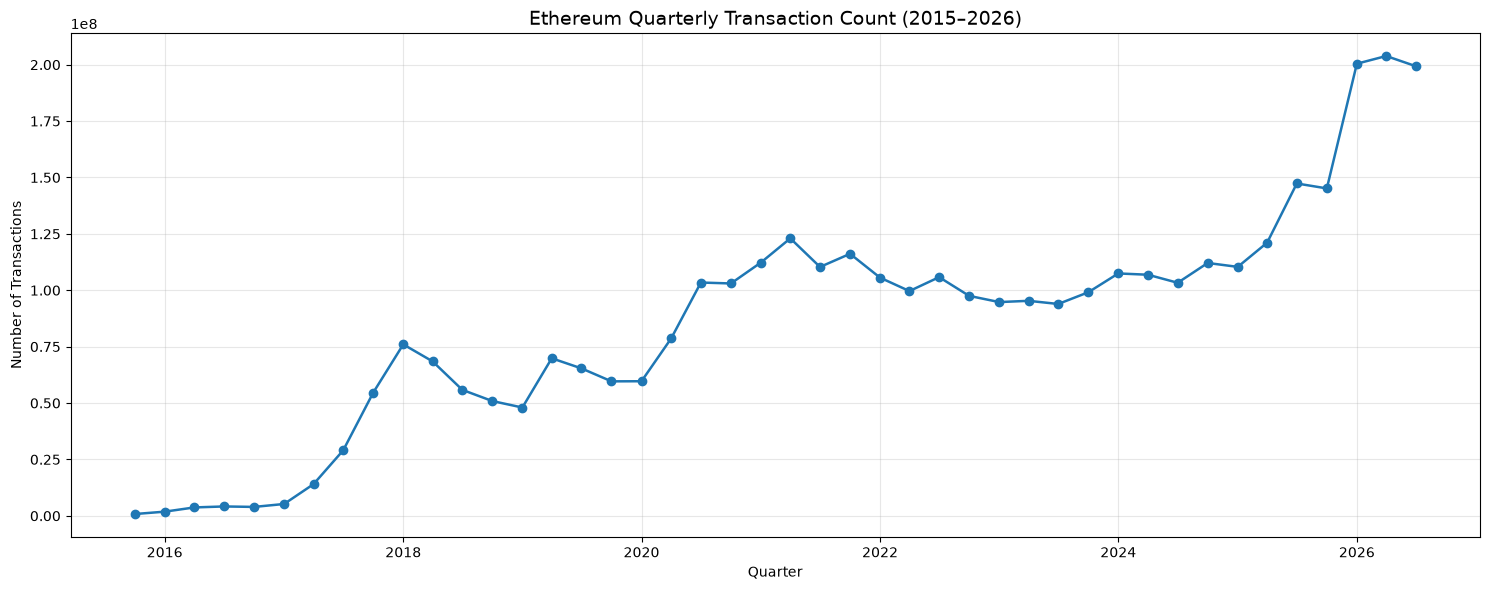

In [7]:
# Plot quarterly transaction activity

plt.figure(figsize=(15, 6))

plt.plot(
    quarterly_df.index,
    quarterly_df["quarter_tx_count"],
    marker="o",
    linewidth=1.8
)

plt.title(
    "Ethereum Quarterly Transaction Count (2015–2026)",
    fontsize=14
)
plt.xlabel("Quarter")
plt.ylabel("Number of Transactions")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "01_quarterly_transaction_count.png",
    dpi=300
)

plt.show()


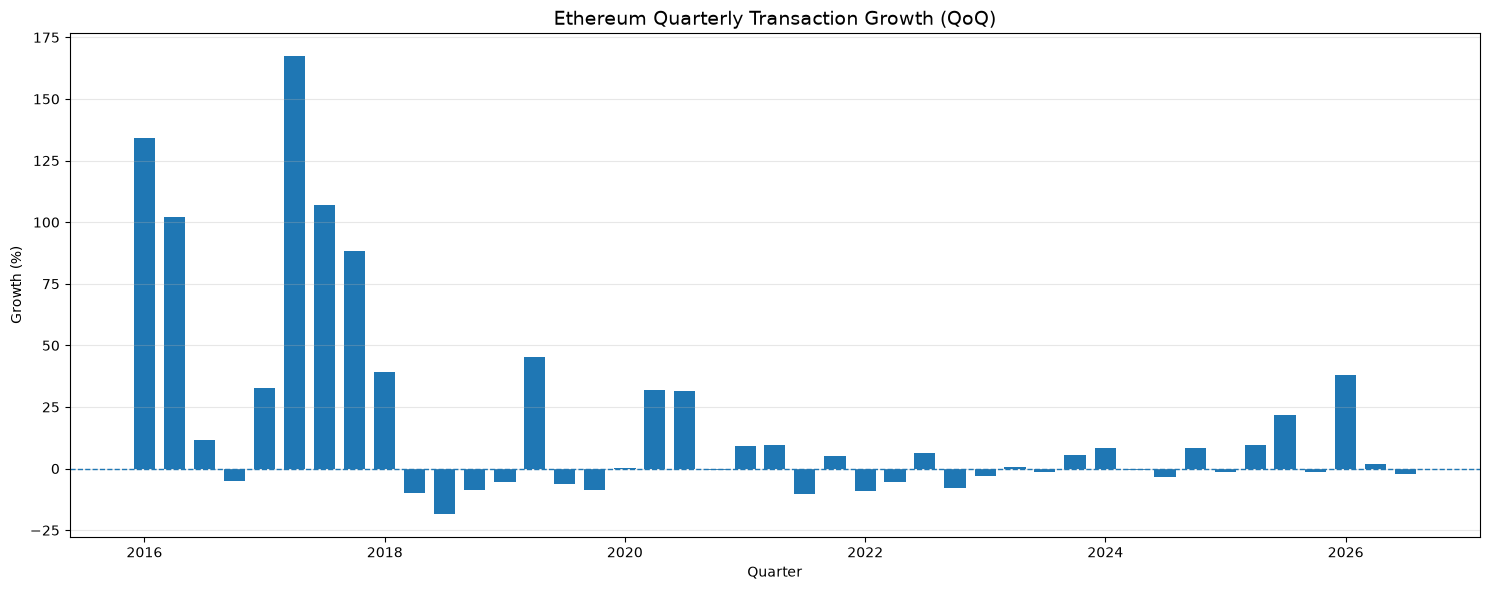

In [8]:
# Plot quarterly QoQ growth

plt.figure(figsize=(15, 6))

plt.bar(
    quarterly_df.index,
    quarterly_df["qoq_growth_pct"],
    width=65
)

plt.axhline(
    y=0,
    linewidth=1,
    linestyle="--"
)

plt.title(
    "Ethereum Quarterly Transaction Growth (QoQ)",
    fontsize=14
)

plt.xlabel("Quarter")
plt.ylabel("Growth (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "02_quarterly_qoq_growth.png",
    dpi=300
)

plt.show()


In [9]:
# Examine the largest quarterly changes

growth_changes = quarterly_df[
    ["qoq_growth_pct"]
].dropna()

print("FIVE LARGEST QUARTERLY INCREASES")
print(
    growth_changes.nlargest(5, "qoq_growth_pct").round(2)
)

print("\nFIVE LARGEST QUARTERLY DECREASES")
print(
    growth_changes.nsmallest(5, "qoq_growth_pct").round(2)
)


FIVE LARGEST QUARTERLY INCREASES
            qoq_growth_pct
month                     
2017-04-01          167.44
2016-01-01          134.10
2017-07-01          106.97
2016-04-01          102.03
2017-10-01           88.12

FIVE LARGEST QUARTERLY DECREASES
            qoq_growth_pct
month                     
2018-07-01          -18.43
2021-07-01          -10.31
2018-04-01           -9.93
2022-01-01           -9.11
2018-10-01           -8.88


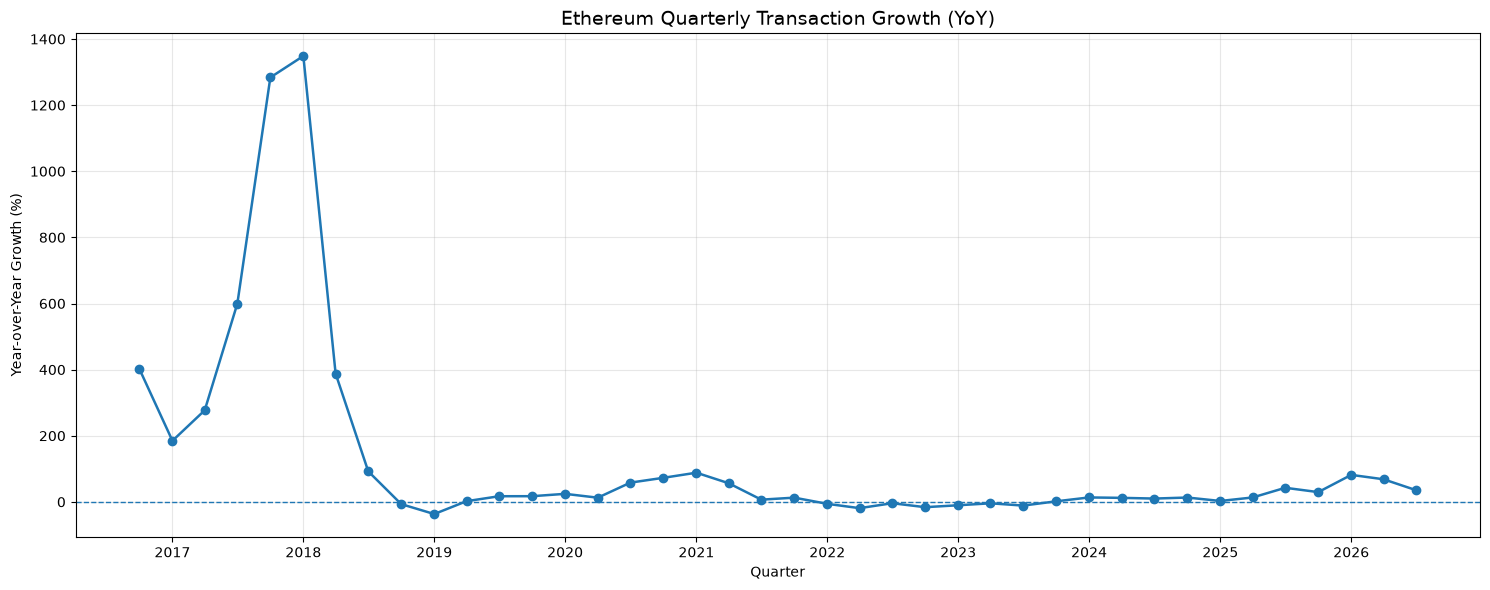

In [10]:
# Examine year-over-year growth

plt.figure(figsize=(15, 6))

plt.plot(
    quarterly_df.index,
    quarterly_df["yoy_growth_pct"],
    marker="o",
    linewidth=1.8
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title(
    "Ethereum Quarterly Transaction Growth (YoY)",
    fontsize=14
)

plt.xlabel("Quarter")
plt.ylabel("Year-over-Year Growth (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "03_quarterly_yoy_growth.png",
    dpi=300
)

plt.show()


In [11]:
# Identify positive and negative YoY quarters

yoy = quarterly_df["yoy_growth_pct"].dropna()

print("Positive-growth quarters:", (yoy > 0).sum())
print("Negative-growth quarters:", (yoy < 0).sum())
print("Zero-growth quarters:", (yoy == 0).sum())

print("\nNEGATIVE YoY GROWTH:")
print(yoy[yoy < 0].round(2))

print("\nLARGEST YoY INCREASES:")
print(yoy.nlargest(5).round(2))


Positive-growth quarters: 31
Negative-growth quarters: 9
Zero-growth quarters: 0

NEGATIVE YoY GROWTH:
month
2018-10-01    -6.86
2019-01-01   -36.82
2022-01-01    -5.99
2022-04-01   -19.00
2022-07-01    -4.09
2022-10-01   -16.06
2023-01-01   -10.25
2023-04-01    -4.34
2023-07-01   -11.24
Name: yoy_growth_pct, dtype: float64

LARGEST YoY INCREASES:
month
2018-01-01    1348.64
2017-10-01    1283.80
2017-07-01     599.71
2016-10-01     401.68
2018-04-01     387.91
Name: yoy_growth_pct, dtype: float64


In [12]:
# Save the quarterly dataset

quarterly_file = (
    processed_dir /
    "ethereum_quarterly_txcount_2015_2026.csv"
)

quarterly_df.to_csv(quarterly_file)

print("Quarterly dataset saved successfully.")
print("File:", quarterly_file)
print("Observations:", len(quarterly_df))


Quarterly dataset saved successfully.
File: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\data\processed\ethereum_quarterly_txcount_2015_2026.csv
Observations: 44


In [13]:
## Quarterly seasonality and trend analysis
# Calculate average transactions by quarter

quarterly_df["quarter_number"] = quarterly_df.index.quarter

seasonal_summary = (
    quarterly_df.groupby("quarter_number")["quarter_tx_count"]
    .agg(["count", "mean", "median", "std"])
)

seasonal_summary.index = [
    "Q1", "Q2", "Q3", "Q4"
]

print("AVERAGE TRANSACTIONS BY CALENDAR QUARTER")
print(seasonal_summary.round(2))


AVERAGE TRANSACTIONS BY CALENDAR QUARTER
    count         mean       median          std
Q1     11  83788511.55   94763301.0  55758116.48
Q2     11  89499189.27   95313768.0  54439073.81
Q3     11  92531673.55  103315009.0  53911962.84
Q4     11  76626561.91   97508049.0  46502671.86


In [14]:
# Calculate quarterly seasonal indices

overall_mean = quarterly_df["quarter_tx_count"].mean()

seasonal_summary["seasonal_index"] = (
    seasonal_summary["mean"] / overall_mean * 100
)

print("OVERALL QUARTERLY MEAN:")
print(round(overall_mean, 2))

print("\nQUARTERLY SEASONAL INDICES:")
print(
    seasonal_summary[
        ["mean", "seasonal_index"]
    ].round(2)
)


OVERALL QUARTERLY MEAN:
85611484.07

QUARTERLY SEASONAL INDICES:
           mean  seasonal_index
Q1  83788511.55           97.87
Q2  89499189.27          104.54
Q3  92531673.55          108.08
Q4  76626561.91           89.51


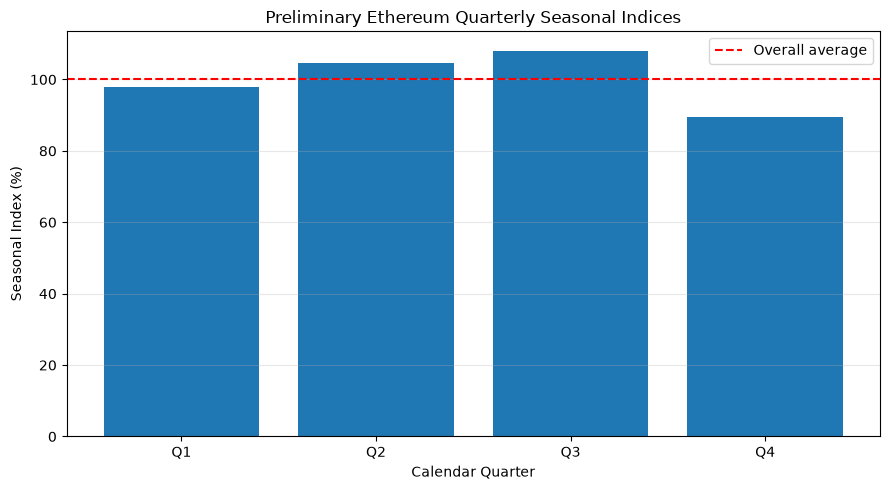

In [16]:
# Visualise the preliminary seasonal indices
plt.figure(figsize=(9, 5))

plt.bar(
    seasonal_summary.index,
    seasonal_summary["seasonal_index"]
)

plt.axhline(
    100,
    color="red",
    linestyle="--",
    label="Overall average"
)

plt.title("Preliminary Ethereum Quarterly Seasonal Indices")
plt.xlabel("Calendar Quarter")
plt.ylabel("Seasonal Index (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "04_quarterly_seasonal_indices.png",
    dpi=300
)

plt.show()

In [17]:
# Remove the long-term trend
quarterly_df["trend_4q"] = (
    quarterly_df["quarter_tx_count"]
    .rolling(window=4, center=True)
    .mean()
)

quarterly_df["detrended_tx_count"] = (
    quarterly_df["quarter_tx_count"]
    / quarterly_df["trend_4q"]
    * 100
)

print("Trend and detrended values calculated.")

print(
    quarterly_df[
        [
            "quarter_tx_count",
            "trend_4q",
            "detrended_tx_count"
        ]
    ].head(10).round(2)
)

Trend and detrended values calculated.
            quarter_tx_count     trend_4q  detrended_tx_count
month                                                        
2015-10-01            786870          NaN                 NaN
2016-01-01           1842026          NaN                 NaN
2016-04-01           3721428   2625096.50              141.76
2016-07-01           4150062   3415270.00              121.51
2016-10-01           3947564   4266309.25               92.53
2017-01-01           5246183   6843487.00               76.66
2017-04-01          14030139  13065545.25              107.38
2017-07-01          29038295  25735258.50              112.83
2017-10-01          54626417  43423240.25              125.80
2018-01-01          75998110  57029242.25              133.26


In [18]:
# Calculate detrended seasonal indices
detrended_summary = (
    quarterly_df
    .dropna(subset=["detrended_tx_count"])
    .groupby(quarterly_df.dropna(
        subset=["detrended_tx_count"]
    ).index.quarter)["detrended_tx_count"]
    .agg(["count", "mean", "median", "std"])
)

detrended_summary.index = ["Q1", "Q2", "Q3", "Q4"]

print("DE-TRENDED QUARTERLY SUMMARY")
print(detrended_summary.round(2))

DE-TRENDED QUARTERLY SUMMARY
    count    mean  median    std
Q1     10  100.13   98.31  15.73
Q2     11  108.49  107.38  12.96
Q3     10  105.68  105.63  11.02
Q4     10  100.54   99.11  10.00


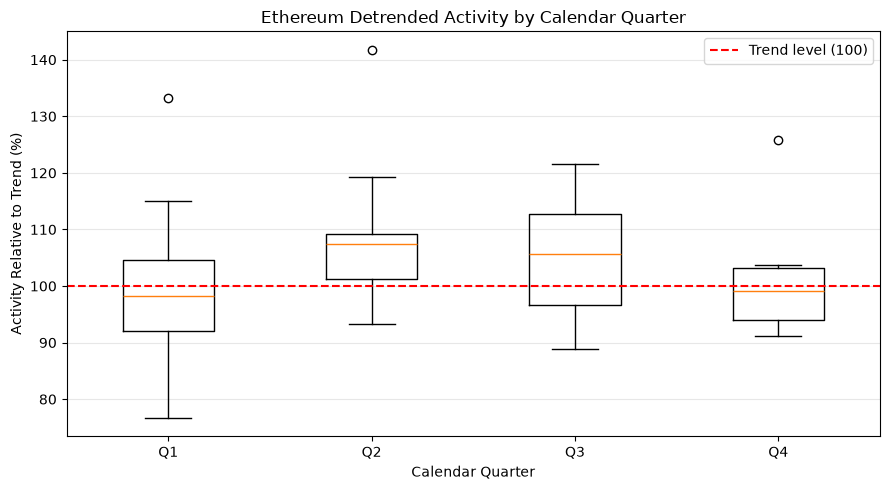

In [19]:
# Visualise detrended quarterly activity
plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        quarterly_df.loc[
            quarterly_df.index.quarter == q,
            "detrended_tx_count"
        ].dropna()
        for q in range(1, 5)
    ],
    tick_labels=["Q1", "Q2", "Q3", "Q4"]
)

plt.axhline(
    100,
    color="red",
    linestyle="--",
    label="Trend level (100)"
)

plt.title("Ethereum Detrended Activity by Calendar Quarter")
plt.xlabel("Calendar Quarter")
plt.ylabel("Activity Relative to Trend (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "05_detrended_quarterly_activity.png",
    dpi=300
)

plt.show()

In [20]:
## Statistical test for quarterly differences
# Kruskal–Wallis test to compare detrended activity across the four quarters
from scipy.stats import kruskal

quarter_groups = [
    quarterly_df.loc[
        quarterly_df.index.quarter == q,
        "detrended_tx_count"
    ].dropna()
    for q in range(1, 5)
]

statistic, p_value = kruskal(*quarter_groups)

print("KRUSKAL-WALLIS TEST")
print("Test statistic:", round(statistic, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Significant differences between quarters.")
else:
    print("Result: No statistically significant differences between quarters.")

KRUSKAL-WALLIS TEST
Test statistic: 4.4049
P-value: 0.2209
Result: No statistically significant differences between quarters.


In [21]:
# Save the detrended seasonal summary
detrended_file = (
    processed_dir /
    "ethereum_detrended_quarterly_summary.csv"
)

detrended_summary.to_csv(detrended_file)

print("Detrended seasonal summary saved.")
print("File:", detrended_file)

Detrended seasonal summary saved.
File: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\data\processed\ethereum_detrended_quarterly_summary.csv


In [22]:
## quarterly time-series decomposition
# Prepare the quarterly series
quarterly_series = quarterly_df["quarter_tx_count"].copy()

quarterly_series = quarterly_series.asfreq("QS")

print("Quarterly time series prepared.")
print("Observations:", len(quarterly_series))
print("Frequency:", quarterly_series.index.freq)
print("Missing values:", quarterly_series.isna().sum())

Quarterly time series prepared.
Observations: 44
Frequency: <QuarterBegin: startingMonth=1>
Missing values: 0


In [23]:
## Perform quarterly decomposition
# classical additive decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    quarterly_series,
    model="additive",
    period=4
)

print("Quarterly decomposition completed.")

Quarterly decomposition completed.


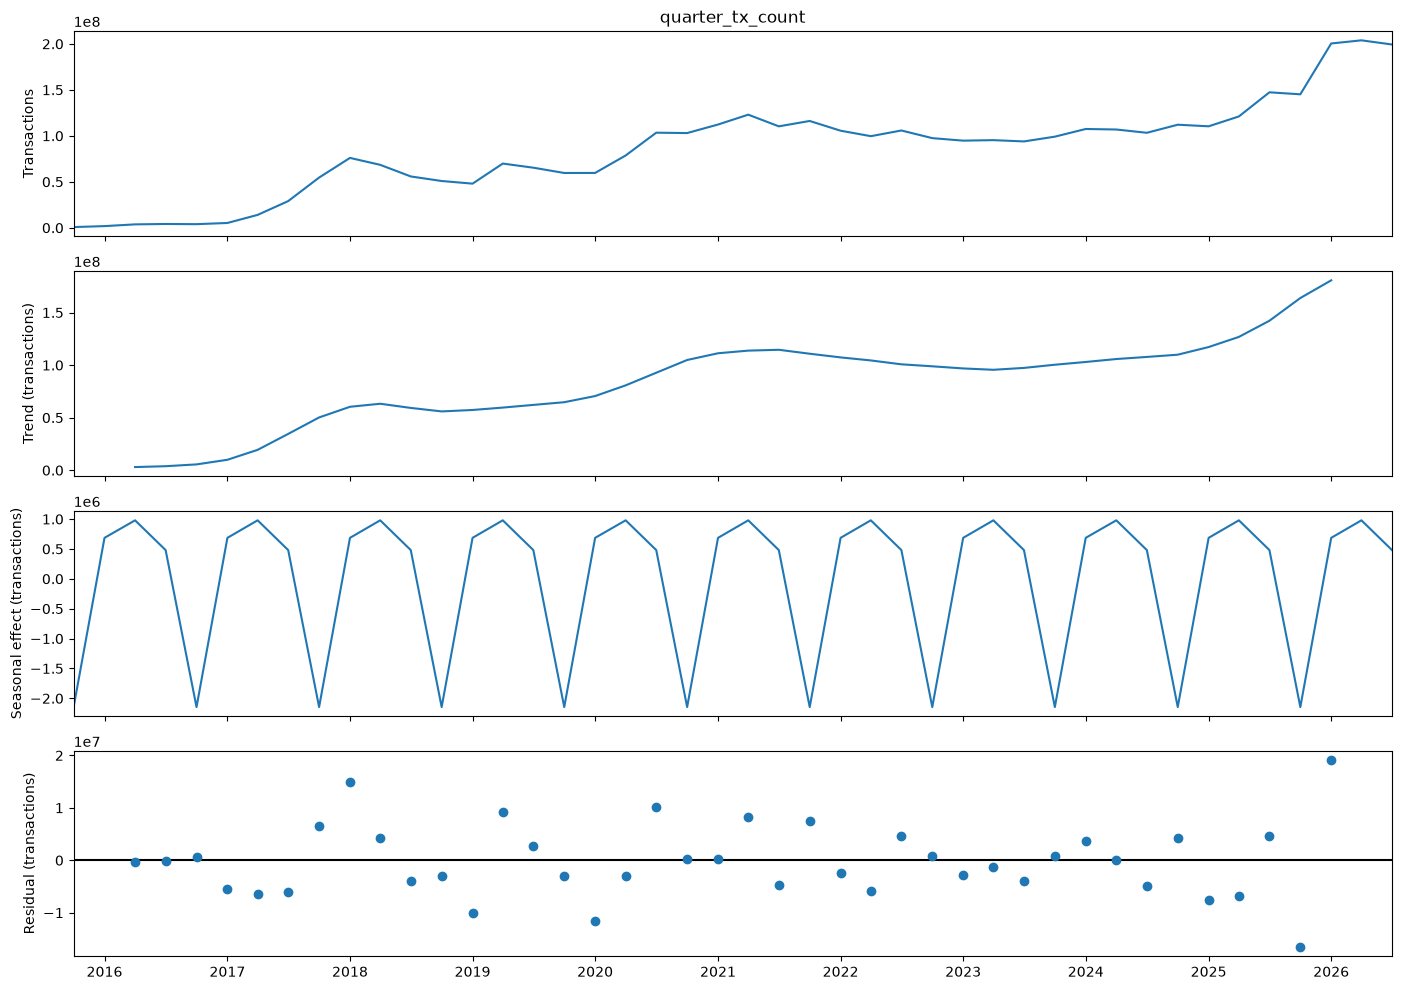

In [25]:
# Plot the decomposition components
fig = decomposition.plot()
fig.set_size_inches(14, 10)

axes = fig.axes

axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Trend (transactions)")
axes[2].set_ylabel("Seasonal effect (transactions)")
axes[3].set_ylabel("Residual (transactions)")

plt.tight_layout()

plt.savefig(
    visualizations_dir / "06_quarterly_time_series_decomposition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
# Examine residual statistics
residuals = decomposition.resid.dropna()

print("RESIDUAL STATISTICS")
print(residuals.describe().round(2))

print("\nResidual mean:", round(residuals.mean(), 2))
print("Residual standard deviation:", round(residuals.std(), 2))
print("Positive residuals:", (residuals > 0).sum())
print("Negative residuals:", (residuals < 0).sum())

RESIDUAL STATISTICS
count          40.00
mean      -173108.00
std       7003547.11
min     -16550454.21
25%      -4812986.53
50%       -224655.15
75%       4236777.19
max      19062327.25
Name: resid, dtype: float64

Residual mean: -173108.0
Residual standard deviation: 7003547.11
Positive residuals: 19
Negative residuals: 21


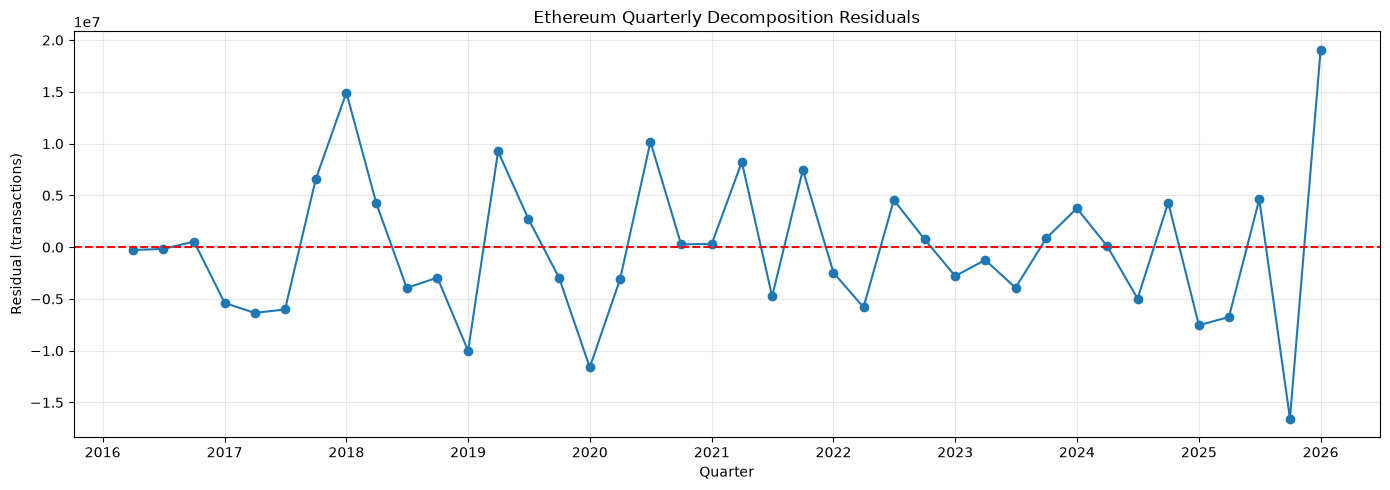

In [27]:
# Plot the residual component
plt.figure(figsize=(14, 5))

plt.plot(
    residuals.index,
    residuals,
    marker="o",
    linewidth=1.5
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Ethereum Quarterly Decomposition Residuals")
plt.xlabel("Quarter")
plt.ylabel("Residual (transactions)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "07_quarterly_decomposition_residuals.png",
    dpi=300
)

plt.show()

In [28]:
# Ljung–Box test for residual autocorrelation
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box_results = acorr_ljungbox(
    residuals,
    lags=[4, 8],
    return_df=True
)

print("LJUNG-BOX TEST")
print(ljung_box_results.round(4))

LJUNG-BOX TEST
   lb_stat  lb_pvalue
4   5.6190     0.2295
8   9.5938     0.2947


In [29]:
## Quarterly stationarity analysis
# Augmented Dickey–Fuller (ADF) test
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(quarterly_series)

print("AUGMENTED DICKEY-FULLER TEST")
print("ADF statistic:", round(adf_result[0], 4))
print("P-value:", round(adf_result[1], 4))
print("Critical values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value:.4f}")

if adf_result[1] < 0.05:
    print("\nConclusion: The series is stationary.")
else:
    print("\nConclusion: The series is non-stationary.")

AUGMENTED DICKEY-FULLER TEST
ADF statistic: -0.1376
P-value: 0.9456
Critical values:
1%: -3.5925
5%: -2.9315
10%: -2.6041

Conclusion: The series is non-stationary.


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_8240\1370555633.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(quarterly_series)


In [30]:
# First-order differencing
quarterly_diff = quarterly_series.diff().dropna()

print("FIRST-ORDER DIFFERENCED SERIES")
print("Observations:", len(quarterly_diff))
print("\nFirst 10 observations:")
print(quarterly_diff.head(10).round(2))

FIRST-ORDER DIFFERENCED SERIES
Observations: 43

First 10 observations:
month
2016-01-01     1055156.0
2016-04-01     1879402.0
2016-07-01      428634.0
2016-10-01     -202498.0
2017-01-01     1298619.0
2017-04-01     8783956.0
2017-07-01    15008156.0
2017-10-01    25588122.0
2018-01-01    21371693.0
2018-04-01    -7543963.0
Freq: QS-JAN, Name: quarter_tx_count, dtype: float64


In [31]:
# ADF test after first-order differencing
adf_diff_result = adfuller(quarterly_diff)

print("ADF TEST — FIRST-ORDER DIFFERENCED SERIES")
print("ADF statistic:", round(adf_diff_result[0], 4))
print("P-value:", round(adf_diff_result[1], 4))

print("\nCritical values:")
for key, value in adf_diff_result[4].items():
    print(f"{key}: {value:.4f}")

if adf_diff_result[1] < 0.05:
    print("\nConclusion: The differenced series is stationary.")
else:
    print("\nConclusion: The differenced series is non-stationary.")

ADF TEST — FIRST-ORDER DIFFERENCED SERIES
ADF statistic: -5.8323
P-value: 0.0

Critical values:
1%: -3.5966
5%: -2.9333
10%: -2.6050

Conclusion: The differenced series is stationary.


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_8240\4103201253.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_result = adfuller(quarterly_diff)


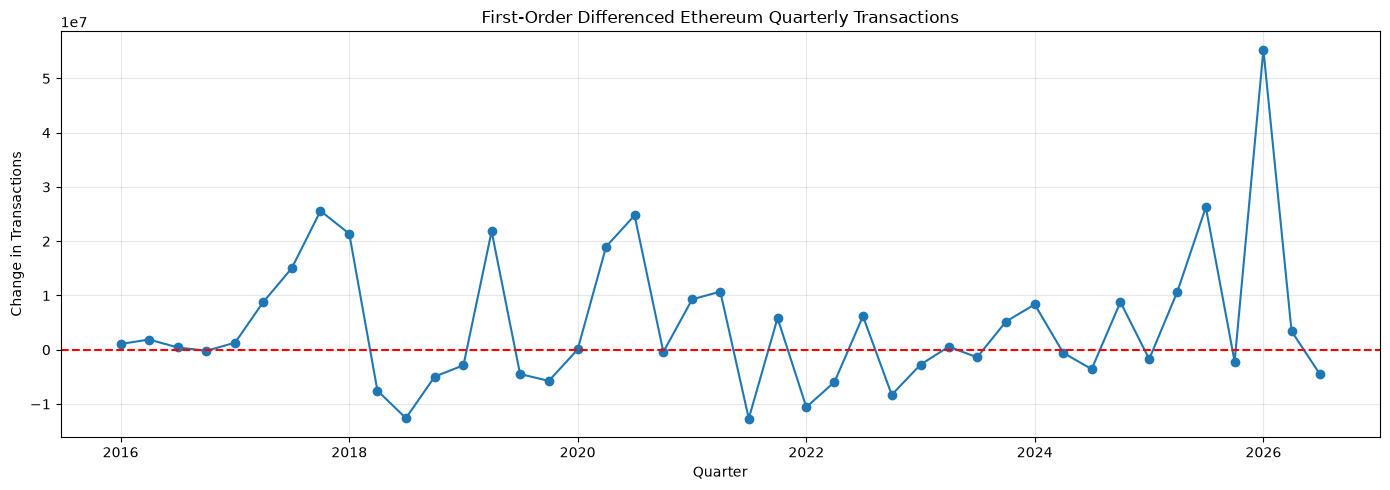

In [32]:
# Examine the differenced series visually
plt.figure(figsize=(14, 5))

plt.plot(
    quarterly_diff.index,
    quarterly_diff,
    marker="o",
    linewidth=1.5
)

plt.axhline(0, color="red", linestyle="--")

plt.title("First-Order Differenced Ethereum Quarterly Transactions")
plt.xlabel("Quarter")
plt.ylabel("Change in Transactions")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "08_quarterly_first_difference.png",
    dpi=300
)

plt.show()

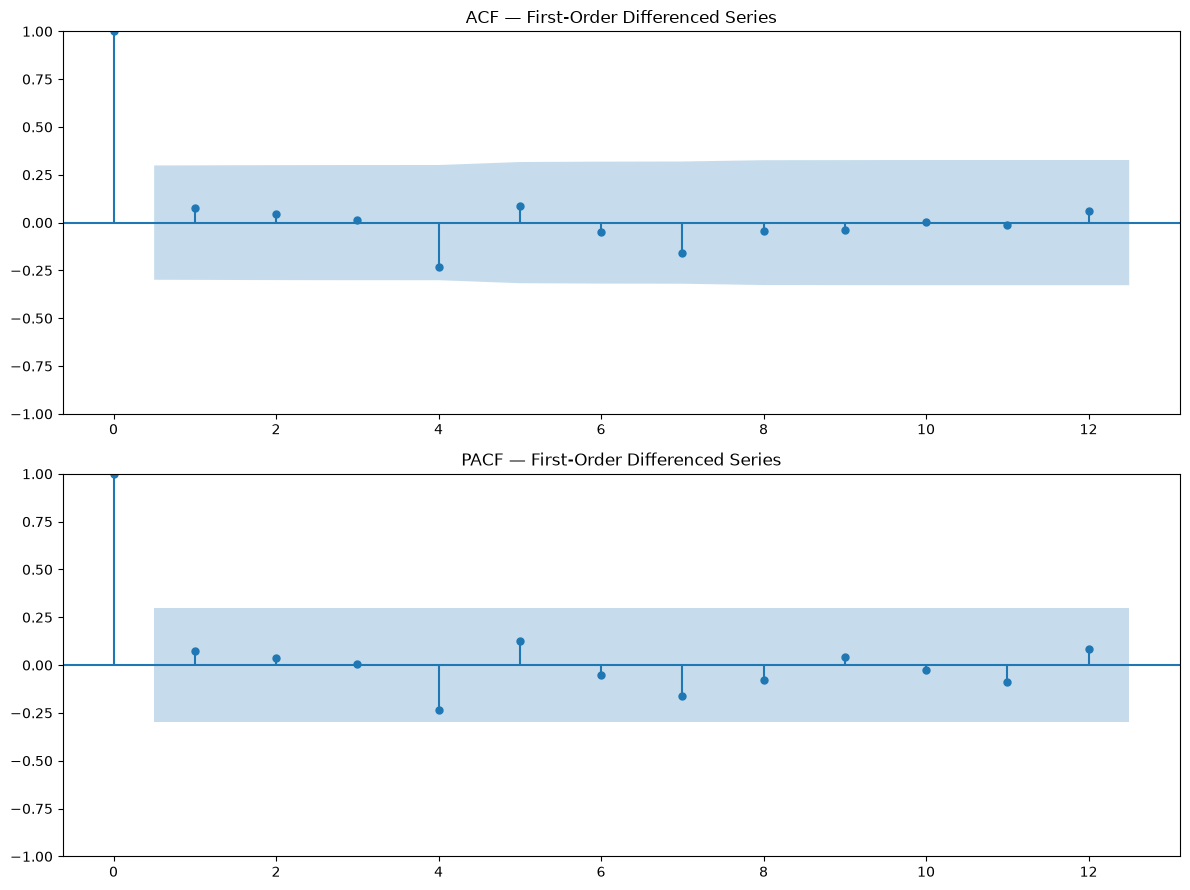

In [33]:
# Plot ACF and PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

plot_acf(
    quarterly_diff,
    lags=12,
    ax=axes[0]
)

axes[0].set_title("ACF — First-Order Differenced Series")

plot_pacf(
    quarterly_diff,
    lags=12,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("PACF — First-Order Differenced Series")

plt.tight_layout()

plt.savefig(
    visualizations_dir / "09_quarterly_acf_pacf.png",
    dpi=300
)

plt.show()

In [34]:
# Fit three ARIMA candidates
from statsmodels.tsa.arima.model import ARIMA

arima_candidates = {
    "ARIMA(0,1,0)": (0, 1, 0),
    "ARIMA(1,1,0)": (1, 1, 0),
    "ARIMA(0,1,1)": (0, 1, 1)
}

arima_results = {}

for name, order in arima_candidates.items():

    model = ARIMA(
        quarterly_series,
        order=order
    )

    fitted_model = model.fit()

    arima_results[name] = fitted_model

    print(
        name,
        "| AIC:", round(fitted_model.aic, 2),
        "| BIC:", round(fitted_model.bic, 2)
    )

ARIMA(0,1,0) | AIC: 1536.46 | BIC: 1538.23
ARIMA(1,1,0) | AIC: 1536.94 | BIC: 1540.46
ARIMA(0,1,1) | AIC: 1537.45 | BIC: 1540.97


In [35]:
# Examine ARIMA(0,1,0) summary
print(arima_results["ARIMA(0,1,0)"].summary())

                               SARIMAX Results                                
Dep. Variable:       quarter_tx_count   No. Observations:                   44
Model:                 ARIMA(0, 1, 0)   Log Likelihood                -767.232
Date:                Sun, 15 Nov 2026   AIC                           1536.464
Time:                        20:29:06   BIC                           1538.226
Sample:                    10-01-2015   HQIC                          1537.114
                         - 07-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2        1.8e+14   2.06e+13      8.744      0.000     1.4e+14     2.2e+14
Ljung-Box (L1) (Q):                   0.26   Jarque-Bera (JB):                45.04
Prob(Q):                              0.61   Pr

In [36]:
# Prepare training and testing datasets
train = quarterly_series.iloc[:-8]
test = quarterly_series.iloc[-8:]

print("TRAINING DATA")
print("Observations:", len(train))
print("Period:", train.index.min(), "to", train.index.max())

print("\nTESTING DATA")
print("Observations:", len(test))
print("Period:", test.index.min(), "to", test.index.max())

TRAINING DATA
Observations: 36
Period: 2015-10-01 00:00:00 to 2024-07-01 00:00:00

TESTING DATA
Observations: 8
Period: 2024-10-01 00:00:00 to 2026-07-01 00:00:00


In [37]:
# Fit models and compare forecast accuracy
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_results = {}

for name, order in arima_candidates.items():

    model = ARIMA(train, order=order)
    fitted = model.fit()

    forecast = fitted.forecast(steps=len(test))

    forecast_results[name] = forecast

# Seasonal naive baseline: repeat the last four quarters
forecast_results["Seasonal Naive"] = pd.Series(
    list(train.iloc[-4:]) * 2,
    index=test.index
)

# Calculate forecast accuracy
accuracy = []

for name, forecast in forecast_results.items():

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    mape = np.mean(np.abs((test - forecast) / test)) * 100

    accuracy.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

accuracy_df = pd.DataFrame(accuracy).set_index("Model")

print("OUT-OF-SAMPLE FORECAST ACCURACY")
print(accuracy_df.round(2).sort_values("RMSE"))

OUT-OF-SAMPLE FORECAST ACCURACY
                        MAE         RMSE  MAPE (%)
Model                                             
Seasonal Naive  50767485.50  62953099.69     28.71
ARIMA(0,1,0)    51641132.50  64118580.03     29.19
ARIMA(0,1,1)    52587258.53  64883013.95     29.84
ARIMA(1,1,0)    53238675.61  65476060.80     30.27


In [38]:
# Compare actual and forecast values
comparison_df = pd.DataFrame({
    "Actual": test,
    "Seasonal Naive": forecast_results["Seasonal Naive"],
    "ARIMA(0,1,0)": forecast_results["ARIMA(0,1,0)"],
    "ARIMA(0,1,1)": forecast_results["ARIMA(0,1,1)"],
    "ARIMA(1,1,0)": forecast_results["ARIMA(1,1,0)"]
})

print("ACTUAL VS FORECAST TRANSACTION COUNTS")
print(comparison_df.round(0).to_string())

comparison_df.to_csv(
    processed_dir / "ethereum_quarterly_forecast_comparison.csv"
)

print("\nForecast comparison saved successfully.")

ACTUAL VS FORECAST TRANSACTION COUNTS
               Actual  Seasonal Naive  ARIMA(0,1,0)  ARIMA(0,1,1)  ARIMA(1,1,0)
2024-10-01  112095697        99104337   103315009.0   102368883.0   102164237.0
2025-01-01  110364282       107452234   103315009.0   102368883.0   101793088.0
2025-04-01  121082115       106883044   103315009.0   102368883.0   101673384.0
2025-07-01  147337159       103315009   103315009.0   102368883.0   101634776.0
2025-10-01  145154396        99104337   103315009.0   102368883.0   101622325.0
2026-01-01  200442726       107452234   103315009.0   102368883.0   101618309.0
2026-04-01  203852887       106883044   103315009.0   102368883.0   101617013.0
2026-07-01  199319870       103315009   103315009.0   102368883.0   101616596.0

Forecast comparison saved successfully.


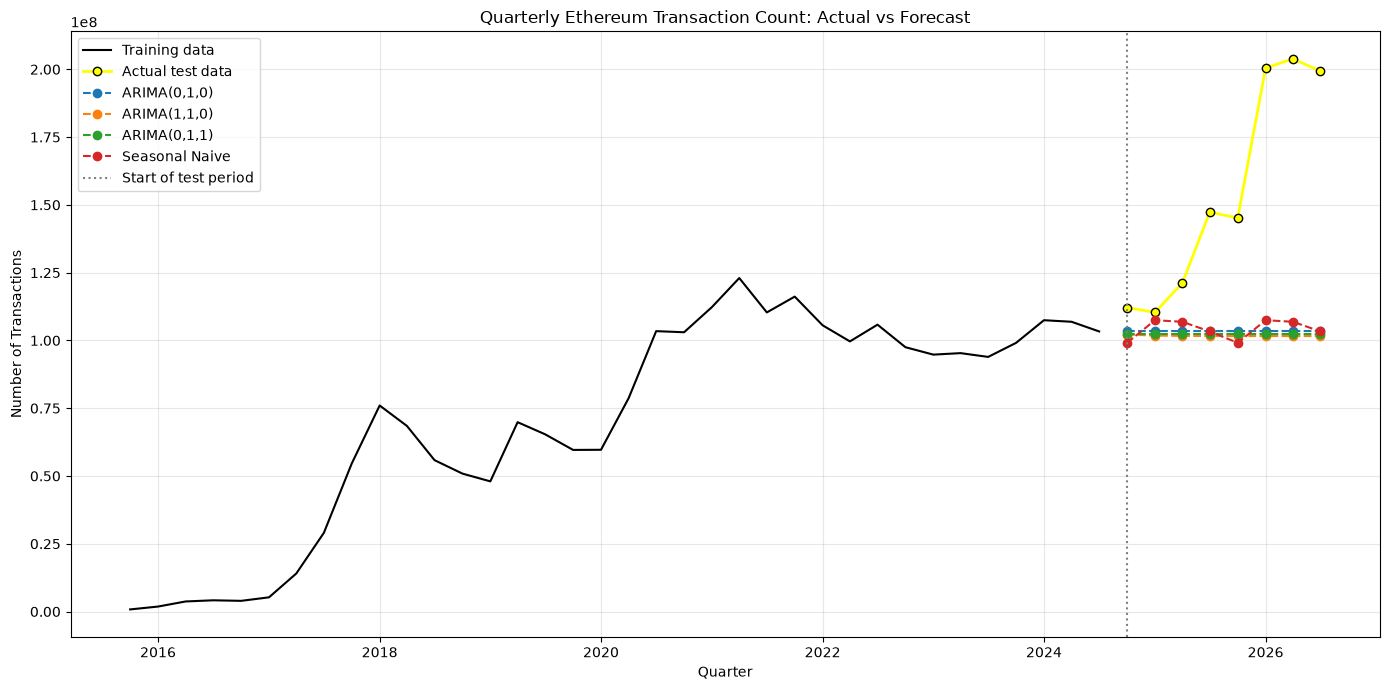

In [40]:
# Plot actual values against forecasts
plt.figure(figsize=(14, 7))

# Historical training data
plt.plot(
    train.index,
    train,
    label="Training data",
    color="black"
)

# Actual test data
plt.plot(
    test.index,
    test,
    label="Actual test data",
    color="yellow",
    marker="o",
    linewidth=2,
    markeredgecolor="black"
)

# Forecasts
for name, forecast in forecast_results.items():
    plt.plot(
        forecast.index,
        forecast,
        marker="o",
        linestyle="--",
        label=name
    )

plt.axvline(
    test.index[0],
    color="gray",
    linestyle=":",
    label="Start of test period"
)

plt.title("Quarterly Ethereum Transaction Count: Actual vs Forecast")
plt.xlabel("Quarter")
plt.ylabel("Number of Transactions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "10_quarterly_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
# ARIMA with drift
# Fit ARIMA(0,1,0) with drift
drift_model = ARIMA(
    train,
    order=(0, 1, 0),
    trend="t"
)

drift_fitted = drift_model.fit()

# Forecast the eight test quarters
drift_forecast = drift_fitted.forecast(
    steps=len(test)
)

# Add to forecast results
forecast_results["ARIMA(0,1,0) with Drift"] = drift_forecast

# Calculate forecast accuracy
drift_mae = mean_absolute_error(test, drift_forecast)
drift_rmse = np.sqrt(mean_squared_error(test, drift_forecast))
drift_mape = np.mean(
    np.abs((test - drift_forecast) / test)
) * 100

print("ARIMA(0,1,0) WITH DRIFT")
print("Estimated drift:", round(drift_fitted.params.iloc[0], 2))
print("\nForecast values:")
print(drift_forecast.round(0))

print("\nForecast accuracy:")
print("MAE:", round(drift_mae, 2))
print("RMSE:", round(drift_rmse, 2))
print("MAPE:", round(drift_mape, 2), "%")

ARIMA(0,1,0) WITH DRIFT
Estimated drift: 2929375.4

Forecast values:
2024-10-01    106244384.0
2025-01-01    109173760.0
2025-04-01    112103135.0
2025-07-01    115032511.0
2025-10-01    117961886.0
2026-01-01    120891261.0
2026-04-01    123820637.0
2026-07-01    126750012.0
Freq: QS-JAN, Name: predicted_mean, dtype: float64

Forecast accuracy:
MAE: 38458943.2
RMSE: 49873942.4
MAPE: 21.22 %


In [42]:
# Compare all five models
accuracy = []

for name, forecast in forecast_results.items():

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))
    mape = np.mean(np.abs((test - forecast) / test)) * 100

    accuracy.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

accuracy_df = pd.DataFrame(accuracy).set_index("Model")

accuracy_df = accuracy_df.sort_values("RMSE")

print("UPDATED OUT-OF-SAMPLE FORECAST ACCURACY")
print(accuracy_df.round(2))

accuracy_df.to_csv(
    processed_dir / "ethereum_quarterly_model_accuracy.csv"
)

UPDATED OUT-OF-SAMPLE FORECAST ACCURACY
                                 MAE         RMSE  MAPE (%)
Model                                                      
ARIMA(0,1,0) with Drift  38458943.20  49873942.40     21.22
Seasonal Naive           50767485.50  62953099.69     28.71
ARIMA(0,1,0)             51641132.50  64118580.03     29.19
ARIMA(0,1,1)             52587258.53  64883013.95     29.84
ARIMA(1,1,0)             53238675.61  65476060.80     30.27


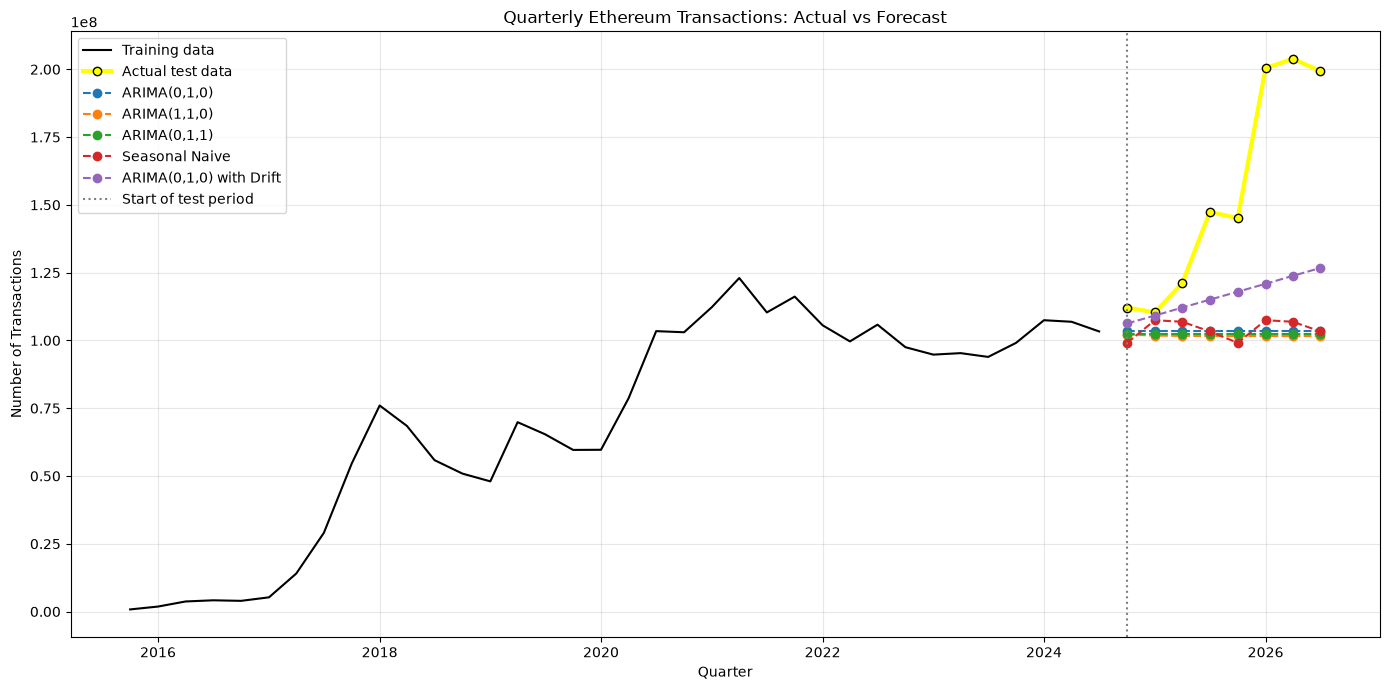

In [43]:
# Updated forecast graph
plt.figure(figsize=(14, 7))

# Historical training data
plt.plot(
    train.index,
    train,
    label="Training data",
    color="black"
)

# Actual test data
plt.plot(
    test.index,
    test,
    label="Actual test data",
    color="yellow",
    marker="o",
    linewidth=3,
    markeredgecolor="black"
)

# All five forecasts
for name, forecast in forecast_results.items():
    plt.plot(
        forecast.index,
        forecast,
        marker="o",
        linestyle="--",
        label=name
    )

plt.axvline(
    test.index[0],
    color="gray",
    linestyle=":",
    label="Start of test period"
)

plt.title("Quarterly Ethereum Transactions: Actual vs Forecast")
plt.xlabel("Quarter")
plt.ylabel("Number of Transactions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "10_quarterly_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
# Quarterly percentage growth
quarterly_growth = quarterly_series.pct_change() * 100

growth_comparison = pd.DataFrame({
    "Transaction_Count": quarterly_series,
    "Growth_Percent": quarterly_growth
})

print("QUARTERLY GROWTH — LAST 16 QUARTERS")
print(growth_comparison.tail(16).round(2))

QUARTERLY GROWTH — LAST 16 QUARTERS
            Transaction_Count  Growth_Percent
month                                        
2022-10-01           97508049           -7.85
2023-01-01           94763301           -2.81
2023-04-01           95313768            0.58
2023-07-01           93919245           -1.46
2023-10-01           99104337            5.52
2024-01-01          107452234            8.42
2024-04-01          106883044           -0.53
2024-07-01          103315009           -3.34
2024-10-01          112095697            8.50
2025-01-01          110364282           -1.54
2025-04-01          121082115            9.71
2025-07-01          147337159           21.68
2025-10-01          145154396           -1.48
2026-01-01          200442726           38.09
2026-04-01          203852887            1.70
2026-07-01          199319870           -2.22


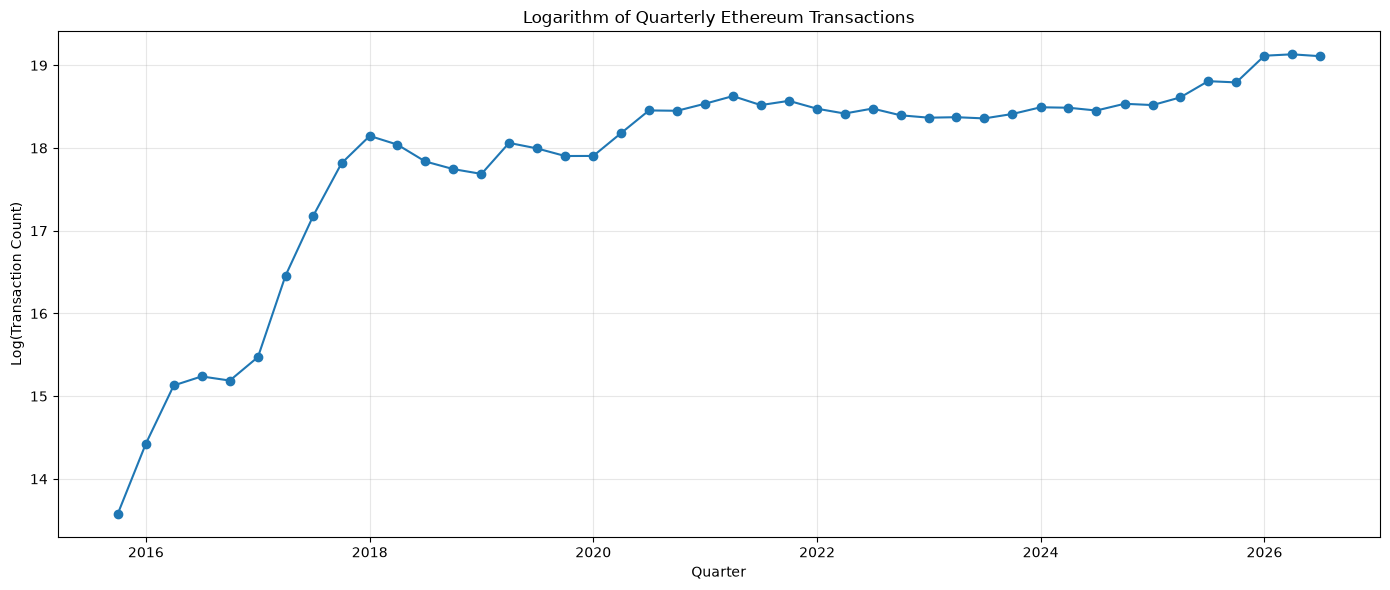

In [45]:
# Logarithmic transformation
quarterly_log = np.log(quarterly_series)

plt.figure(figsize=(14, 6))

plt.plot(
    quarterly_log.index,
    quarterly_log,
    marker="o"
)

plt.title("Logarithm of Quarterly Ethereum Transactions")
plt.xlabel("Quarter")
plt.ylabel("Log(Transaction Count)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "11_quarterly_log_transformation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
# ADF stationarity test on log-transformed data
from statsmodels.tsa.stattools import adfuller

log_adf_result = adfuller(quarterly_log)

print("ADF TEST — LOG-TRANSFORMED SERIES")
print("ADF Statistic:", round(log_adf_result[0], 4))
print("p-value:", round(log_adf_result[1], 4))
print("Critical Values:")

for key, value in log_adf_result[4].items():
    print(f"{key}: {value:.4f}")

ADF TEST — LOG-TRANSFORMED SERIES
ADF Statistic: -5.5844
p-value: 0.0
Critical Values:
1%: -3.5925
5%: -2.9315
10%: -2.6041


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_8240\3240708055.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  log_adf_result = adfuller(quarterly_log)


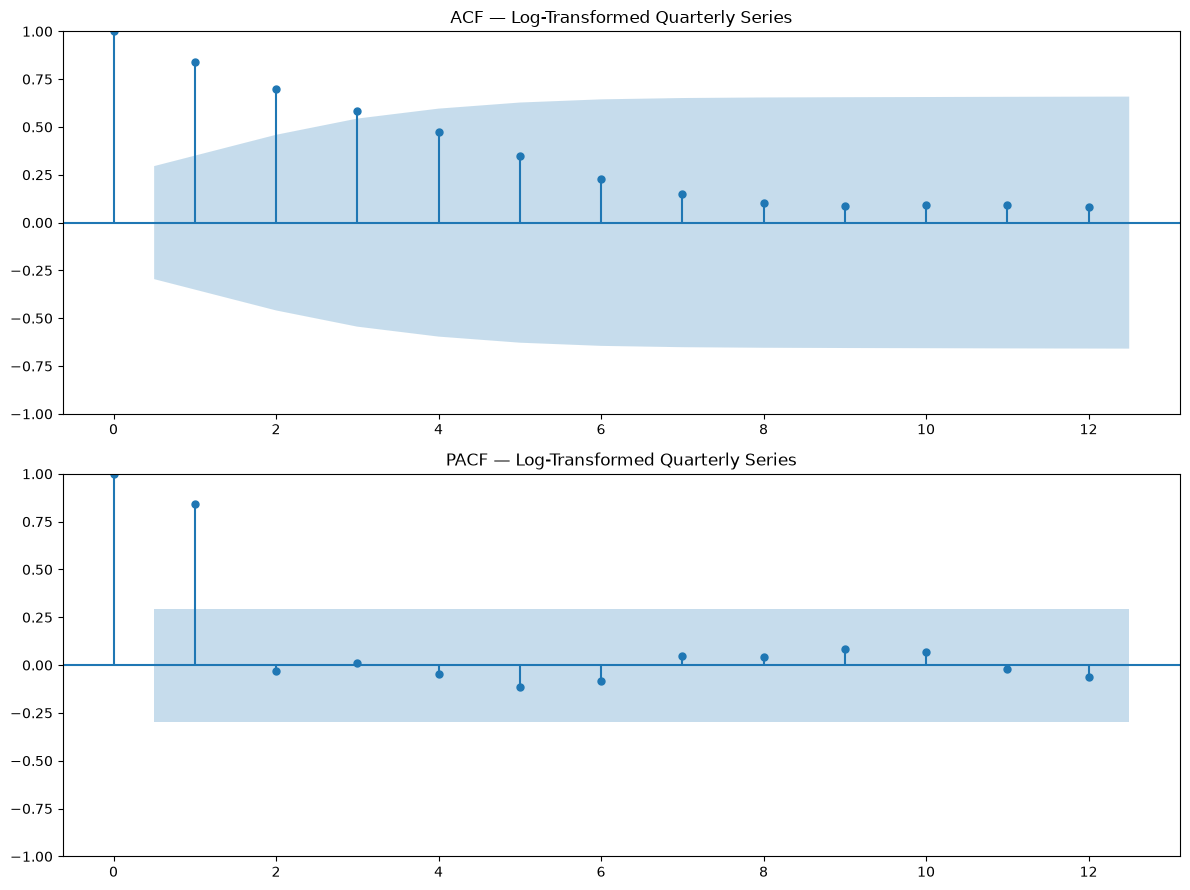

In [47]:
# Inspect ACF and PACF of the log series
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

plot_acf(quarterly_log, lags=12, ax=axes[0])
axes[0].set_title("ACF — Log-Transformed Quarterly Series")

plot_pacf(
    quarterly_log,
    lags=12,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("PACF — Log-Transformed Quarterly Series")

plt.tight_layout()

plt.savefig(
    visualizations_dir / "12_quarterly_log_acf_pacf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [48]:
# Fit ARMA candidates to the log series
log_candidates = {
    "ARMA(1,0)": (1, 0, 0),
    "ARMA(2,0)": (2, 0, 0),
    "ARMA(3,0)": (3, 0, 0),
    "ARMA(1,1)": (1, 0, 1),
    "ARMA(2,1)": (2, 0, 1)
}

log_model_results = {}

for name, order in log_candidates.items():

    model = ARIMA(quarterly_log, order=order)
    fitted = model.fit()

    log_model_results[name] = fitted

    print(
        name,
        "| AIC:", round(fitted.aic, 2),
        "| BIC:", round(fitted.bic, 2)
    )

ARMA(1,0) | AIC: 29.61 | BIC: 34.96
ARMA(2,0) | AIC: 6.64 | BIC: 13.77
ARMA(3,0) | AIC: 7.4 | BIC: 16.32
ARMA(1,1) | AIC: 11.36 | BIC: 18.49
ARMA(2,1) | AIC: 7.45 | BIC: 16.37


In [49]:
# Inspect ARMA(2,0) model
print(log_model_results["ARMA(2,0)"].summary())

                               SARIMAX Results                                
Dep. Variable:       quarter_tx_count   No. Observations:                   44
Model:                 ARIMA(2, 0, 0)   Log Likelihood                   0.681
Date:                Sun, 15 Nov 2026   AIC                              6.638
Time:                        20:43:25   BIC                             13.775
Sample:                    10-01-2015   HQIC                             9.284
                         - 07-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         16.4644      2.307      7.137      0.000      11.943      20.986
ar.L1          1.7055      0.112     15.261      0.000       1.487       1.925
ar.L2         -0.7171      0.101     -7.069      0.0

In [50]:
## Test ARMA(2,0) on the holdout data
# ARMA(2,0) out-of-sample forecast
# Fit ARMA(2,0) on training data only
arma2_model = ARIMA(
    np.log(train),
    order=(2, 0, 0)
)

arma2_fitted = arma2_model.fit()

# Forecast eight quarters in log scale
arma2_log_forecast = arma2_fitted.forecast(
    steps=len(test)
)

# Convert forecasts back to transaction counts
arma2_forecast = np.exp(arma2_log_forecast)

# Store forecast
forecast_results["ARMA(2,0) Log"] = arma2_forecast

# Calculate accuracy
arma2_mae = mean_absolute_error(test, arma2_forecast)

arma2_rmse = np.sqrt(
    mean_squared_error(test, arma2_forecast)
)

arma2_mape = np.mean(
    np.abs((test - arma2_forecast) / test)
) * 100

print("ARMA(2,0) — LOG TRANSFORMATION")
print("\nForecast values:")
print(arma2_forecast.round(0))

print("\nForecast accuracy:")
print("MAE:", round(arma2_mae, 2))
print("RMSE:", round(arma2_rmse, 2))
print("MAPE:", round(arma2_mape, 2), "%")

ARMA(2,0) — LOG TRANSFORMATION

Forecast values:
2024-10-01    97353604.0
2025-01-01    90100333.0
2025-04-01    82379701.0
2025-07-01    74747261.0
2025-10-01    67539633.0
2026-01-01    60933600.0
2026-04-01    54998486.0
2026-07-01    49736631.0
Freq: QS-JAN, Name: predicted_mean, dtype: float64

Forecast accuracy:
MAE: 82732485.31
RMSE: 98370951.51
MAPE: 47.99 %


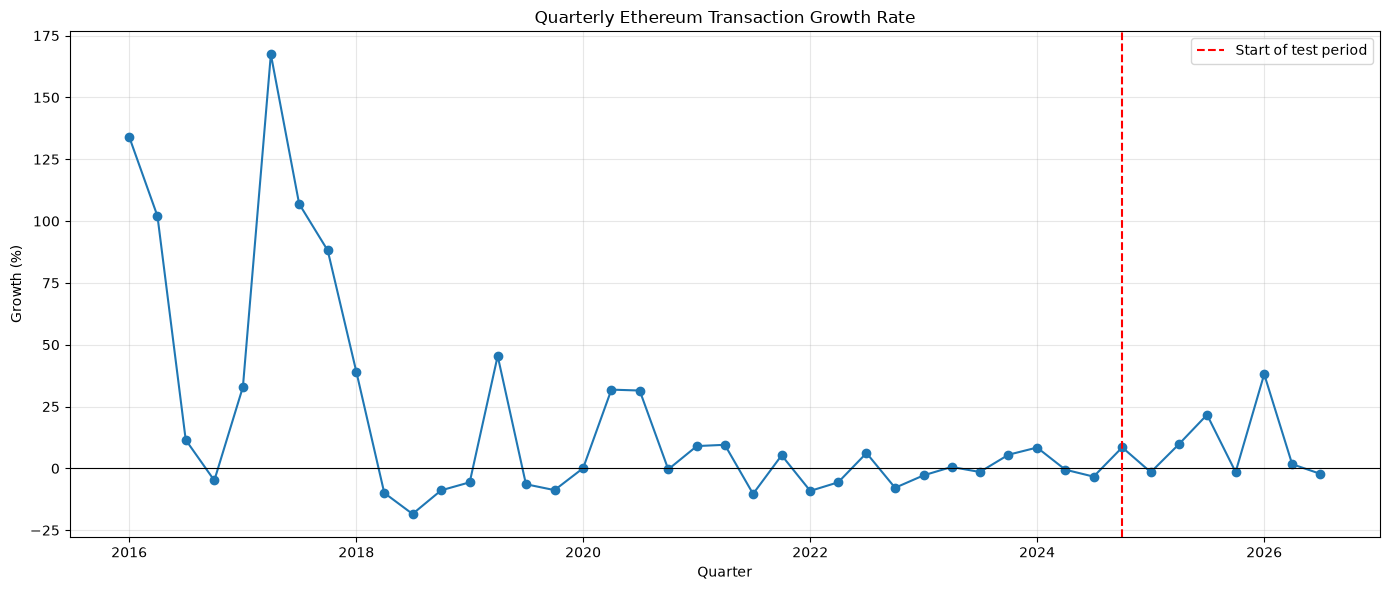

In [51]:
## Investigate structural breaks
# Visualize the quarterly growth rate
plt.figure(figsize=(14, 6))

plt.plot(
    quarterly_growth.index,
    quarterly_growth,
    marker="o",
    linewidth=1.5
)

plt.axhline(0, color="black", linewidth=0.8)

plt.axvline(
    pd.Timestamp("2024-10-01"),
    color="red",
    linestyle="--",
    label="Start of test period"
)

plt.title("Quarterly Ethereum Transaction Growth Rate")
plt.xlabel("Quarter")
plt.ylabel("Growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "13_quarterly_growth_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [4]:
## this is next day, to continue:
# Re-establish the project directories
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_dir = Path(
    r"E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026"
)

processed_dir = project_dir / "data" / "processed"
visualizations_dir = project_dir / "visualizations"
reports_dir = project_dir / "reports"

print("Project directory exists:", project_dir.exists())
print("Processed directory exists:", processed_dir.exists())
print("Quarterly CSV exists:", (
    processed_dir / "ethereum_quarterly_txcount_2015_2026.csv"
).exists())

Project directory exists: True
Processed directory exists: True
Quarterly CSV exists: True


In [7]:
# Reload the quarterly dataset
quarterly_df = pd.read_csv(
    quarterly_file,
    parse_dates=["month"]
)

quarterly_df = quarterly_df.set_index("month").sort_index()

quarterly_series = quarterly_df["quarter_tx_count"].asfreq("QS")

quarterly_log = np.log(quarterly_series)

quarterly_growth = quarterly_series.pct_change() * 100

print("Quarterly data restored successfully.")
print("Observations:", len(quarterly_series))
print("First quarter:", quarterly_series.index.min())
print("Last quarter:", quarterly_series.index.max())
print("Missing values:", quarterly_series.isna().sum())

Quarterly data restored successfully.
Observations: 44
First quarter: 2015-10-01 00:00:00
Last quarter: 2026-07-01 00:00:00
Missing values: 0


In [8]:
## Structural break analysis
# test Q4 2024 (October 2024) as a candidate break date
import statsmodels.api as sm
from scipy.stats import f

# Prepare the log-transformed quarterly series
y = quarterly_log.dropna().values
time = np.arange(len(y))

# Candidate structural break
break_date = pd.Timestamp("2024-10-01")
break_index = quarterly_log.index.get_loc(break_date)

print("Observations:", len(y))
print("Candidate break:", break_date.date())
print("Observations before break:", break_index)
print("Observations from break onward:", len(y) - break_index)

Observations: 44
Candidate break: 2024-10-01
Observations before break: 36
Observations from break onward: 8


In [9]:
# Perform the Chow structural break test
# Regression without a structural break
X_full = sm.add_constant(time)
model_full = sm.OLS(y, X_full).fit()

# Regression before the candidate break
X_pre = sm.add_constant(time[:break_index])
model_pre = sm.OLS(y[:break_index], X_pre).fit()

# Regression from the candidate break onward
X_post = sm.add_constant(time[break_index:])
model_post = sm.OLS(y[break_index:], X_post).fit()

# Calculate residual sum of squares
rss_full = np.sum(model_full.resid ** 2)

rss_separate = (
    np.sum(model_pre.resid ** 2)
    + np.sum(model_post.resid ** 2)
)

# Chow test statistic
k = X_full.shape[1]
n = len(y)

chow_f = (
    ((rss_full - rss_separate) / k)
    / (rss_separate / (n - 2 * k))
)

p_value = f.sf(chow_f, k, n - 2 * k)

print("CHOW STRUCTURAL BREAK TEST")
print("--------------------------")
print("Candidate break:", break_date.date())
print("F-statistic:", round(chow_f, 4))
print("p-value:", f"{p_value:.6f}")

if p_value < 0.05:
    print("Result: Evidence of a structural break.")
else:
    print("Result: Insufficient evidence of a structural break.")

CHOW STRUCTURAL BREAK TEST
--------------------------
Candidate break: 2024-10-01
F-statistic: 3.0116
p-value: 0.060486
Result: Insufficient evidence of a structural break.


In [10]:
# Examine the two regression trends
print("PRE-BREAK REGRESSION")
print("--------------------")
print("Intercept:", round(model_pre.params[0], 4))
print("Trend coefficient:", round(model_pre.params[1], 4))
print("R-squared:", round(model_pre.rsquared, 4))

print("\nPOST-BREAK REGRESSION")
print("---------------------")
print("Intercept:", round(model_post.params[0], 4))
print("Trend coefficient:", round(model_post.params[1], 4))
print("R-squared:", round(model_post.rsquared, 4))

PRE-BREAK REGRESSION
--------------------
Intercept: 15.8366
Trend coefficient: 0.1012
R-squared: 0.6212

POST-BREAK REGRESSION
---------------------
Intercept: 14.7871
Trend coefficient: 0.1023
R-squared: 0.9061


In [11]:
## trend
# Fit the linear and quadratic trend models
# Prepare the log-transformed series
y = quarterly_log.dropna()

time = np.arange(len(y))

# Centre time to improve numerical stability
time_centered = time - time.mean()

# Linear trend model
X_linear = sm.add_constant(time_centered)

linear_model = sm.OLS(y, X_linear).fit()

# Quadratic trend model
X_quadratic = sm.add_constant(
    np.column_stack([
        time_centered,
        time_centered ** 2
    ])
)

quadratic_model = sm.OLS(y, X_quadratic).fit()

# Compare model results
print("LINEAR TREND MODEL")
print("------------------")
print("R-squared:", round(linear_model.rsquared, 4))
print("Adjusted R-squared:", round(linear_model.rsquared_adj, 4))
print("AIC:", round(linear_model.aic, 4))
print("BIC:", round(linear_model.bic, 4))

print("\nQUADRATIC TREND MODEL")
print("--------------------")
print("R-squared:", round(quadratic_model.rsquared, 4))
print("Adjusted R-squared:", round(quadratic_model.rsquared_adj, 4))
print("AIC:", round(quadratic_model.aic, 4))
print("BIC:", round(quadratic_model.bic, 4))

# Test whether the quadratic term improves the model
print("\nNESTED MODEL COMPARISON")
print("----------------------")
print(quadratic_model.compare_f_test(linear_model))

LINEAR TREND MODEL
------------------
R-squared: 0.6236
Adjusted R-squared: 0.6146
AIC: 108.9064
BIC: 112.4748

QUADRATIC TREND MODEL
--------------------
R-squared: 0.8353
Adjusted R-squared: 0.8273
AIC: 74.5255
BIC: 79.8781

NESTED MODEL COMPARISON
----------------------
(np.float64(52.72933052439859), np.float64(7.061407676846677e-09), np.float64(1.0))


In [12]:
# Evaluate forecasting performance on the holdout data
# reserve the final eight quarters (Q4 2024–Q3 2026) as test data
# refit both models using only the first 36 quarters.
# This prevents information from the test period leaking into the model
# Train/test split: last 8 quarters for testing
train_size = len(quarterly_log) - 8

train_log = quarterly_log.iloc[:train_size]
test_log = quarterly_log.iloc[train_size:]

test_actual = quarterly_series.iloc[train_size:]

# Time indices
time_train = np.arange(len(train_log))
time_test = np.arange(train_size, len(quarterly_log))

# Centre time using training data only
time_mean = time_train.mean()

x_train = time_train - time_mean
x_test = time_test - time_mean

# Linear trend
X_train_linear = sm.add_constant(x_train)
X_test_linear = sm.add_constant(x_test)

linear_train_model = sm.OLS(
    train_log.values,
    X_train_linear
).fit()

linear_log_forecast = linear_train_model.predict(X_test_linear)

# Quadratic trend
X_train_quadratic = sm.add_constant(
    np.column_stack([x_train, x_train ** 2])
)

X_test_quadratic = sm.add_constant(
    np.column_stack([x_test, x_test ** 2])
)

quadratic_train_model = sm.OLS(
    train_log.values,
    X_train_quadratic
).fit()

quadratic_log_forecast = quadratic_train_model.predict(
    X_test_quadratic
)

# Convert log forecasts back to transaction counts
linear_forecast = np.exp(linear_log_forecast)
quadratic_forecast = np.exp(quadratic_log_forecast)

# Calculate forecast accuracy
def forecast_metrics(actual, predicted):
    errors = actual.values - predicted

    return {
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "MAPE (%)": np.mean(
            np.abs(errors / actual.values)
        ) * 100
    }

linear_results = forecast_metrics(
    test_actual, linear_forecast
)

quadratic_results = forecast_metrics(
    test_actual, quadratic_forecast
)

forecast_comparison = pd.DataFrame(
    [linear_results, quadratic_results],
    index=["Linear Trend", "Quadratic Trend"]
)

print("OUT-OF-SAMPLE FORECAST COMPARISON")
print("--------------------------------")
print(forecast_comparison.round(2))

OUT-OF-SAMPLE FORECAST COMPARISON
--------------------------------
                          MAE          RMSE  MAPE (%)
Linear Trend     2.667112e+08  2.739840e+08    173.86
Quadratic Trend  1.263050e+08  1.361278e+08     78.24


In [13]:
# Examine actual versus predicted transactions
# Compare actual and forecast values
forecast_table = pd.DataFrame(
    {
        "Actual": test_actual,
        "Linear_Forecast": linear_forecast,
        "Quadratic_Forecast": quadratic_forecast
    },
    index=test_actual.index
)

forecast_table["Quadratic_Error_%"] = (
    (forecast_table["Actual"] -
     forecast_table["Quadratic_Forecast"])
    / forecast_table["Actual"] * 100
)

print("ACTUAL VS FORECASTED TRANSACTIONS")
print("---------------------------------")

print(forecast_table.round(0).to_string())

ACTUAL VS FORECASTED TRANSACTIONS
---------------------------------
               Actual  Linear_Forecast  Quadratic_Forecast  Quadratic_Error_%
month                                                                        
2024-10-01  112095697      288121785.0          52093034.0               54.0
2025-01-01  110364282      318798016.0          43678296.0               60.0
2025-04-01  121082115      352740337.0          36092093.0               70.0
2025-07-01  147337159      390296484.0          29391300.0               80.0
2025-10-01  145154396      431851223.0          23587715.0               84.0
2026-01-01  200442726      477830281.0          18655774.0               91.0
2026-04-01  203852887      528704714.0          14541226.0               93.0
2026-07-01  199319870      584995731.0          11169896.0               94.0


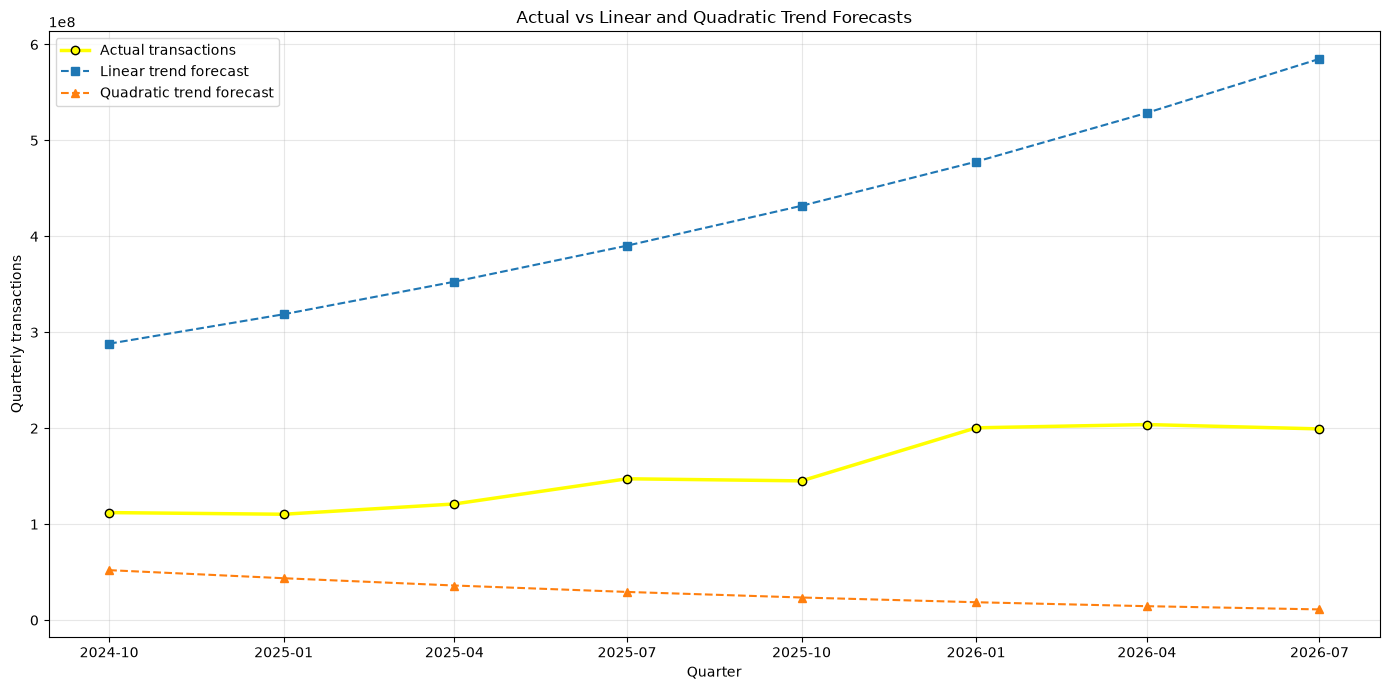

In [14]:
# Visualise the forecasts
plt.figure(figsize=(14, 7))

plt.plot(
    forecast_table.index,
    forecast_table["Actual"],
    marker="o",
    color="yellow",
    markeredgecolor="black",
    linewidth=2.5,
    label="Actual transactions"
)

plt.plot(
    forecast_table.index,
    forecast_table["Linear_Forecast"],
    marker="s",
    linestyle="--",
    label="Linear trend forecast"
)

plt.plot(
    forecast_table.index,
    forecast_table["Quadratic_Forecast"],
    marker="^",
    linestyle="--",
    label="Quadratic trend forecast"
)

plt.title("Actual vs Linear and Quadratic Trend Forecasts")
plt.xlabel("Quarter")
plt.ylabel("Quarterly transactions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "15_quadratic_trend_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
## the piecewise linear trend model
# Prepare the time variable and select a candidate breakpoint
# Prepare training data
train_size = len(quarterly_log) - 8
train_log = quarterly_log.iloc[:train_size].dropna()

# Create time index
time_train = np.arange(len(train_log))

# Candidate breakpoint: Q4 2022
break_date = pd.Timestamp("2022-10-01")
break_index = train_log.index.get_loc(break_date)

print("Training observations:", len(train_log))
print("Training period:", train_log.index.min(), "to", train_log.index.max())
print("Breakpoint:", train_log.index[break_index])
print("Observations before breakpoint:", break_index)
print("Observations from breakpoint onward:", len(train_log) - break_index)

Training observations: 36
Training period: 2015-10-01 00:00:00 to 2024-07-01 00:00:00
Breakpoint: 2022-10-01 00:00:00
Observations before breakpoint: 28
Observations from breakpoint onward: 8


In [16]:
# Fit the piecewise linear model
# Create piecewise trend variables
post_break = (time_train >= break_index).astype(int)

time_after_break = np.maximum(time_train - break_index, 0)

# Design matrix
X_piecewise = sm.add_constant(
    np.column_stack([
        time_train,
        post_break,
        time_after_break
    ])
)

# Fit model
piecewise_model = sm.OLS(
    train_log.values,
    X_piecewise
).fit()

print(piecewise_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.756
Model:                            OLS   Adj. R-squared:                  0.733
Method:                 Least Squares   F-statistic:                     32.96
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           6.60e-10
Time:                        10:00:15   Log-Likelihood:                -36.088
No. Observations:                  36   AIC:                             80.18
Df Residuals:                      32   BIC:                             86.51
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.3385      0.257     59.590      0.0

In [17]:
# compare model fit
model_comparison = pd.DataFrame(
    {
        "Linear Trend": [
            linear_train_model.rsquared,
            linear_train_model.rsquared_adj,
            linear_train_model.aic,
            linear_train_model.bic
        ],
        "Piecewise Linear": [
            piecewise_model.rsquared,
            piecewise_model.rsquared_adj,
            piecewise_model.aic,
            piecewise_model.bic
        ]
    },
    index=["R-squared", "Adjusted R-squared", "AIC", "BIC"]
)

print(model_comparison.round(4))

                    Linear Trend  Piecewise Linear
R-squared                 0.6212            0.7555
Adjusted R-squared        0.6101            0.7326
AIC                      91.9395           80.1756
BIC                      95.1066           86.5097


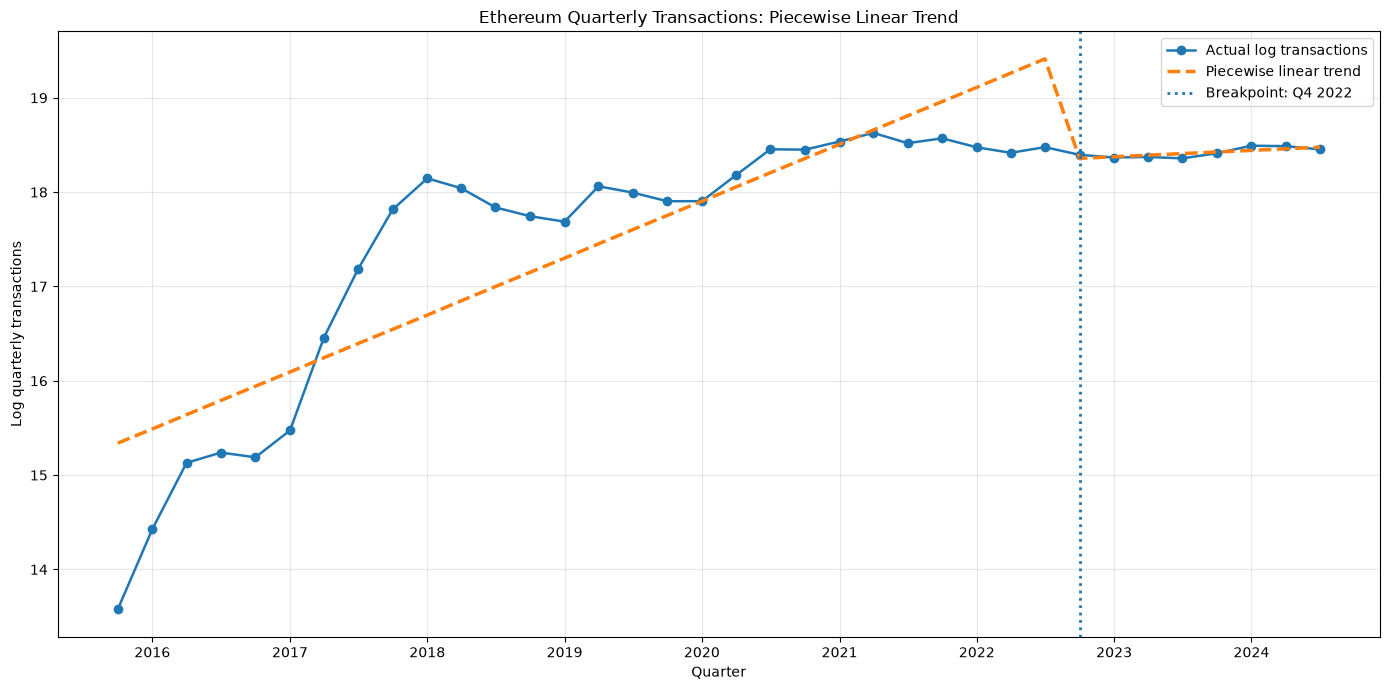

In [18]:
# visualize the fitted trends
# Fitted values in log scale
piecewise_fitted = piecewise_model.predict(X_piecewise)

plt.figure(figsize=(14, 7))

plt.plot(
    train_log.index,
    train_log.values,
    marker="o",
    linewidth=1.8,
    label="Actual log transactions"
)

plt.plot(
    train_log.index,
    piecewise_fitted,
    linestyle="--",
    linewidth=2.5,
    label="Piecewise linear trend"
)

plt.axvline(
    break_date,
    linestyle=":",
    linewidth=2,
    label="Breakpoint: Q4 2022"
)

plt.title("Ethereum Quarterly Transactions: Piecewise Linear Trend")
plt.xlabel("Quarter")
plt.ylabel("Log quarterly transactions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "16_piecewise_linear_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Generate piecewise forecasts
# Create test-period time variables
post_break_test = (time_test >= break_index).astype(int)

time_after_break_test = np.maximum(
    time_test - break_index, 0
)

# Construct test design matrix with an explicit intercept
X_test_piecewise = np.column_stack([
    np.ones(len(time_test)),
    time_test,
    post_break_test,
    time_after_break_test
])

# Predict log transactions
piecewise_log_forecast = piecewise_model.predict(
    X_test_piecewise
)

# Convert predictions back to transaction counts
piecewise_forecast = np.exp(piecewise_log_forecast)

print(pd.DataFrame({
    "Actual": test_actual.values,
    "Piecewise_Forecast": piecewise_forecast
}, index=test_actual.index).round(0))

               Actual  Piecewise_Forecast
month                                    
2024-10-01  112095697         107531337.0
2025-01-01  110364282         109364649.0
2025-04-01  121082115         111229218.0
2025-07-01  147337159         113125577.0
2025-10-01  145154396         115054266.0
2026-01-01  200442726         117015838.0
2026-04-01  203852887         119010853.0
2026-07-01  199319870         121039881.0


In [21]:
# Compare forecasting accuracy
piecewise_results = forecast_metrics(
    test_actual,
    piecewise_forecast
)

all_forecast_results = pd.DataFrame(
    [
        linear_results,
        quadratic_results,
        piecewise_results
    ],
    index=[
        "Linear Trend",
        "Quadratic Trend",
        "Piecewise Linear Trend"
    ]
)

print(all_forecast_results.round(2))

                                 MAE          RMSE  MAPE (%)
Linear Trend            2.667112e+08  2.739840e+08    173.86
Quadratic Trend         1.263050e+08  1.361278e+08     78.24
Piecewise Linear Trend  4.078469e+07  5.301101e+07     22.45


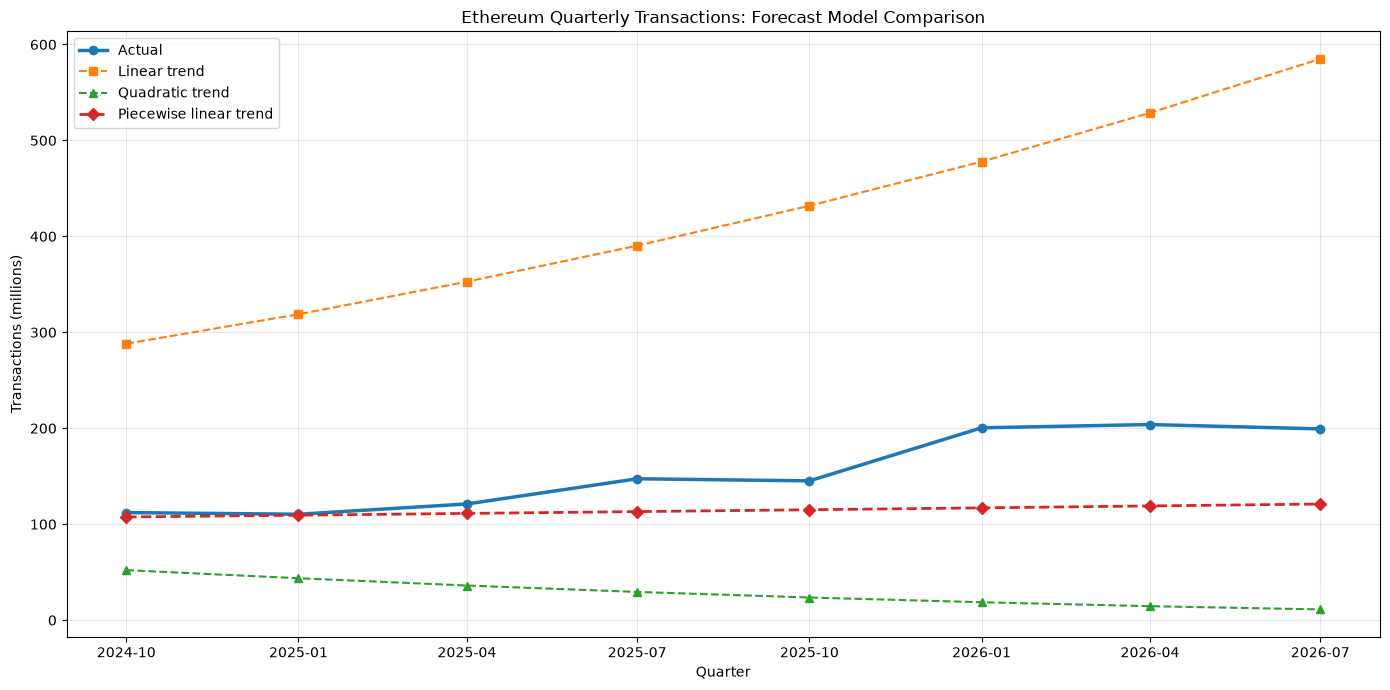

In [22]:
# visualize all three forecasts
plt.figure(figsize=(14, 7))

plt.plot(
    test_actual.index,
    test_actual.values / 1e6,
    marker="o",
    linewidth=2.5,
    label="Actual"
)

plt.plot(
    test_actual.index,
    linear_forecast / 1e6,
    marker="s",
    linestyle="--",
    label="Linear trend"
)

plt.plot(
    test_actual.index,
    quadratic_forecast / 1e6,
    marker="^",
    linestyle="--",
    label="Quadratic trend"
)

plt.plot(
    test_actual.index,
    piecewise_forecast / 1e6,
    marker="D",
    linestyle="--",
    linewidth=2,
    label="Piecewise linear trend"
)

plt.title("Ethereum Quarterly Transactions: Forecast Model Comparison")
plt.xlabel("Quarter")
plt.ylabel("Transactions (millions)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "17_trend_forecast_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
## test the logarithmic time trend model
# Prepare the logarithmic time trend
# Create time indices (start at 1 to avoid log(0))
time_train_log = np.arange(1, len(train_log) + 1)
time_test_log = np.arange(
    len(train_log) + 1,
    len(train_log) + len(test_log) + 1
)

# Log-transform the time indices
log_time_train = np.log(time_train_log)
log_time_test = np.log(time_test_log)

print("Training observations:", len(log_time_train))
print("Test observations:", len(log_time_test))
print("Training time range:", time_train_log[0], "to", time_train_log[-1])
print("Test time range:", time_test_log[0], "to", time_test_log[-1])

Training observations: 36
Test observations: 8
Training time range: 1 to 36
Test time range: 37 to 44


In [24]:
# Fit the logarithmic time trend model
# Add intercept
X_log_train = sm.add_constant(log_time_train)
X_log_test = np.column_stack([
    np.ones(len(log_time_test)),
    log_time_test
])

# Fit logarithmic time trend
log_trend_model = sm.OLS(
    train_log.values,
    X_log_train
).fit()

# Display model summary
print(log_trend_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.891
Model:                            OLS   Adj. R-squared:                  0.888
Method:                 Least Squares   F-statistic:                     278.4
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           6.06e-18
Time:                        10:23:36   Log-Likelihood:                -21.522
No. Observations:                  36   AIC:                             47.04
Df Residuals:                      34   BIC:                             50.21
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.6843      0.247     55.417      0.0

In [25]:
## Generate logarithmic trend forecasts
# Predict log transactions for the test period
log_time_forecast = log_trend_model.predict(X_log_test)

# Convert predictions back to transaction counts
log_trend_forecast = np.exp(log_time_forecast)

# Calculate forecast accuracy
log_trend_results = forecast_metrics(
    test_actual,
    log_trend_forecast
)

print("Logarithmic Time Trend Forecast:")
print(pd.DataFrame({
    "Actual": test_actual.values,
    "Forecast": log_trend_forecast
}, index=test_actual.index).round(0))

print("\nForecast accuracy:")
print(pd.Series(log_trend_results).round(2))

Logarithmic Time Trend Forecast:
               Actual     Forecast
month                             
2024-10-01  112095697  180599516.0
2025-01-01  110364282  187847041.0
2025-04-01  121082115  195185812.0
2025-07-01  147337159  202614594.0
2025-10-01  145154396  210132199.0
2026-01-01  200442726  217737484.0
2026-04-01  203852887  225429346.0
2026-07-01  199319870  233206725.0

Forecast accuracy:
MAE         51637948.27
RMSE        56323163.66
MAPE (%)          38.88
dtype: float64


In [26]:
# Update our model comparison
all_forecast_results = pd.DataFrame(
    [
        linear_results,
        quadratic_results,
        log_trend_results,
        piecewise_results
    ],
    index=[
        "Linear Trend",
        "Quadratic Trend",
        "Logarithmic Time Trend",
        "Piecewise Linear Trend"
    ]
)

print(all_forecast_results.round(2))

                                 MAE          RMSE  MAPE (%)
Linear Trend            2.667112e+08  2.739840e+08    173.86
Quadratic Trend         1.263050e+08  1.361278e+08     78.24
Logarithmic Time Trend  5.163795e+07  5.632316e+07     38.88
Piecewise Linear Trend  4.078469e+07  5.301101e+07     22.45


In [27]:
# Fit exponential trend model
exponential_model = sm.OLS(
    train_log.values,
    sm.add_constant(time_train)
).fit()

# Model summary
print(exponential_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.621
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     55.76
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.15e-08
Time:                        10:32:31   Log-Likelihood:                -43.970
No. Observations:                  36   AIC:                             91.94
Df Residuals:                      34   BIC:                             95.11
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.8366      0.276     57.432      0.0

In [28]:
# test a genuinely different model: the local linear trend model, 
# which allows the underlying level and growth rate to evolve over time
from statsmodels.tsa.statespace.structural import UnobservedComponents

local_linear_model = UnobservedComponents(
    train_log,
    level="local linear trend"
)

local_linear_results = local_linear_model.fit(disp=False)

print(local_linear_results.summary())

                        Unobserved Components Results                         
Dep. Variable:       quarter_tx_count   No. Observations:                   36
Model:             local linear trend   Log Likelihood                  -0.683
Date:                Mon, 16 Nov 2026   AIC                              7.366
Time:                        10:38:38   BIC                             11.945
Sample:                    10-01-2015   HQIC                             8.928
                         - 07-01-2024                                         
Covariance Type:                  opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
sigma2.irregular  3.019e-11      0.013   2.27e-09      1.000      -0.026       0.026
sigma2.level      1.948e-11      0.052   3.77e-10      1.000      -0.101       0.101
sigma2.trend         0.0609 

In [29]:
# generate the eight-quarter forecast
local_forecast_obj = local_linear_results.get_forecast(
    steps=len(test_log)
)

local_linear_log_forecast = local_forecast_obj.predicted_mean

local_linear_forecast = np.exp(local_linear_log_forecast)

local_linear_results_metrics = forecast_metrics(
    test_actual,
    local_linear_forecast
)

print("Local Linear Trend Forecast Accuracy")
print("-------------------------------------")

for metric, value in local_linear_results_metrics.items():
    print(f"{metric}: {value:,.2f}")

Local Linear Trend Forecast Accuracy
-------------------------------------
MAE: 66,010,943.71
RMSE: 79,649,662.09
MAPE (%): 37.95


In [30]:
## rolling-origin validation
# Rather than testing many more trend specifications against the same eight
# quarters, evaluate the leading models using rolling-origin validation.
# one-quarter-ahead rolling-origin validation for the two leading 
# models (Piecewise linear trend & Logarithmic time trend)
rolling_predictions = []

break_date = pd.Timestamp("2022-10-01")
break_index = quarterly_log.index.get_loc(break_date)

for i in range(len(quarterly_log) - 8, len(quarterly_log)):

    train_values = quarterly_log.iloc[:i].values
    actual_value = quarterly_series.iloc[i]
    forecast_date = quarterly_series.index[i]

    time_train = np.arange(i)
    time_next = np.array([i])

    # Piecewise linear trend
    post_train = (time_train >= break_index).astype(int)
    after_train = np.maximum(time_train - break_index, 0)

    X_piecewise_train = np.column_stack([
        np.ones(i), time_train, post_train, after_train
    ])

    piecewise_fit = sm.OLS(
        train_values, X_piecewise_train
    ).fit()

    post_next = (time_next >= break_index).astype(int)
    after_next = np.maximum(time_next - break_index, 0)

    X_piecewise_next = np.column_stack([
        np.ones(1), time_next, post_next, after_next
    ])

    piecewise_prediction = np.exp(
        piecewise_fit.predict(X_piecewise_next)[0]
    )

    # Logarithmic time trend
    log_time_train = np.log(np.arange(1, i + 1))
    log_time_next = np.log(np.array([i + 1]))

    X_log_train = np.column_stack([
        np.ones(i), log_time_train
    ])

    X_log_next = np.column_stack([
        np.ones(1), log_time_next
    ])

    log_time_fit = sm.OLS(
        train_values, X_log_train
    ).fit()

    log_time_prediction = np.exp(
        log_time_fit.predict(X_log_next)[0]
    )

    rolling_predictions.append({
        "quarter": forecast_date,
        "actual": actual_value,
        "piecewise_forecast": piecewise_prediction,
        "log_time_forecast": log_time_prediction
    })

rolling_df = pd.DataFrame(rolling_predictions).set_index("quarter")

print(rolling_df.round(0).to_string())

               actual  piecewise_forecast  log_time_forecast
quarter                                                     
2024-10-01  112095697         107531337.0        180599516.0
2025-01-01  110364282         111404035.0        182581582.0
2025-04-01  121082115         113192456.0        184181600.0
2025-07-01  147337159         118244727.0        186566697.0
2025-10-01  145154396         130100445.0        190778241.0
2026-01-01  200442726         138751515.0        194561301.0
2026-04-01  203852887         159505882.0        201452364.0
2026-07-01  199319870         178093123.0        208234320.0


In [31]:
# calculate rolling-origin accuracy
rolling_metrics = pd.DataFrame({
    "Piecewise Linear": forecast_metrics(
        rolling_df["actual"],
        rolling_df["piecewise_forecast"]
    ),
    "Logarithmic Time": forecast_metrics(
        rolling_df["actual"],
        rolling_df["log_time_forecast"]
    )
}).T

print(rolling_metrics.round(2).to_string())

                          MAE         RMSE  MAPE (%)
Piecewise Linear  23113139.77  30373074.80     13.10
Logarithmic Time  38233798.09  46944075.18     30.66


In [32]:
# compare against simple benchmarks
rolling_df["naive_forecast"] = [
    quarterly_series.iloc[quarterly_series.index.get_loc(date) - 1]
    for date in rolling_df.index
]

rolling_df["seasonal_naive_forecast"] = [
    quarterly_series.iloc[quarterly_series.index.get_loc(date) - 4]
    for date in rolling_df.index
]

benchmark_metrics = pd.DataFrame({
    "Piecewise Linear": forecast_metrics(
        rolling_df["actual"], rolling_df["piecewise_forecast"]
    ),
    "Naive": forecast_metrics(
        rolling_df["actual"], rolling_df["naive_forecast"]
    ),
    "Seasonal Naive": forecast_metrics(
        rolling_df["actual"], rolling_df["seasonal_naive_forecast"]
    )
}).T

print(benchmark_metrics.round(2).to_string())

                          MAE         RMSE  MAPE (%)
Piecewise Linear  23113139.77  30373074.80     13.10
Naive             14112406.38  22299212.12      8.64
Seasonal Naive    41501906.88  51328629.15     23.78


In [33]:
# inspect quarter-by-quarter errors
error_comparison = rolling_df[
    ["actual", "naive_forecast", "piecewise_forecast"]
].copy()

for model in ["naive_forecast", "piecewise_forecast"]:
    error_comparison[f"{model}_error"] = (
        error_comparison["actual"] - error_comparison[model]
    )

    error_comparison[f"{model}_APE"] = (
        error_comparison[f"{model}_error"].abs()
        / error_comparison["actual"] * 100
    )

print(error_comparison.round(2).to_string())

               actual  naive_forecast  piecewise_forecast  naive_forecast_error  naive_forecast_APE  piecewise_forecast_error  piecewise_forecast_APE
quarter                                                                                                                                              
2024-10-01  112095697       103315009        1.075313e+08               8780688                7.83                4564360.21                    4.07
2025-01-01  110364282       112095697        1.114040e+08              -1731415                1.57               -1039752.60                    0.94
2025-04-01  121082115       110364282        1.131925e+08              10717833                8.85                7889659.24                    6.52
2025-07-01  147337159       121082115        1.182447e+08              26255044               17.82               29092432.48                   19.75
2025-10-01  145154396       147337159        1.301004e+08              -2182763                1.50 

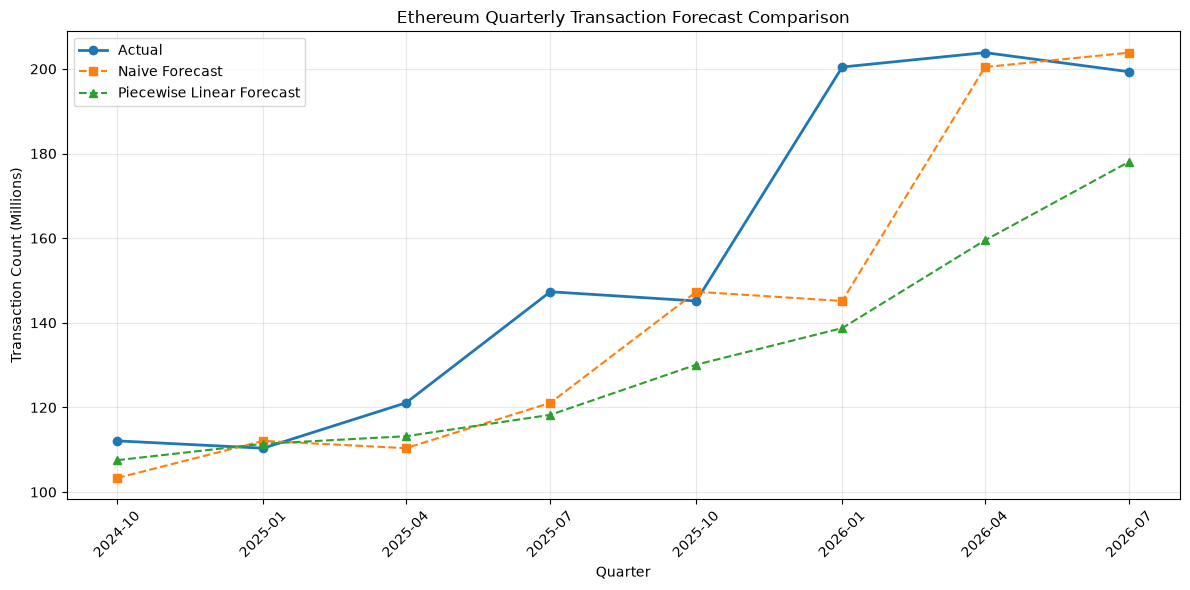

In [34]:
# visualize actual versus predicted values
plt.figure(figsize=(12, 6))

plt.plot(
    rolling_df.index,
    rolling_df["actual"] / 1e6,
    marker="o",
    linewidth=2,
    label="Actual"
)

plt.plot(
    rolling_df.index,
    rolling_df["naive_forecast"] / 1e6,
    marker="s",
    linestyle="--",
    label="Naive Forecast"
)

plt.plot(
    rolling_df.index,
    rolling_df["piecewise_forecast"] / 1e6,
    marker="^",
    linestyle="--",
    label="Piecewise Linear Forecast"
)

plt.title("Ethereum Quarterly Transaction Forecast Comparison")
plt.xlabel("Quarter")
plt.ylabel("Transaction Count (Millions)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    visualizations_dir / "17_rolling_origin_forecast_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
# Obtain historical ETH/USD prices
import requests

url = "https://coins.llama.fi/prices/first/coingecko:ethereum"

response = requests.get(url, timeout=30)
response.raise_for_status()

eth_data = response.json()
print(eth_data)

{'coins': {'coingecko:ethereum': {'symbol': 'ETH', 'price': 2.83162, 'timestamp': 1438905600}}}


In [39]:
# Download and aggregate ETH prices
start = int(pd.Timestamp("2015-10-01", tz="UTC").timestamp())

url = "https://coins.llama.fi/chart/coingecko:ethereum"

response = requests.get(
    url,
    params={
        "start": start,
        "span": 4018,
        "period": "1d"
    },
    timeout=60
)

print("HTTP status:", response.status_code)
print(response.text[:500])

HTTP status: 400
{"message":"Requested 4018 data points exceeds the maximum of 500."}


In [40]:
# Download historical prices in batches
import requests
import pandas as pd

start = int(pd.Timestamp("2015-10-01", tz="UTC").timestamp())
end = int(pd.Timestamp("2026-10-01", tz="UTC").timestamp())

url = "https://coins.llama.fi/chart/coingecko:ethereum"

all_prices = []
current_start = start

while current_start < end:

    response = requests.get(
        url,
        params={
            "start": current_start,
            "span": 450,
            "period": "1d"
        },
        timeout=60
    )

    response.raise_for_status()

    prices = response.json()["coins"]["coingecko:ethereum"]["prices"]

    if not prices:
        break

    all_prices.extend(prices)

    last_timestamp = prices[-1]["timestamp"]

    if last_timestamp <= current_start:
        break

    current_start = last_timestamp + 86400

eth_df = pd.DataFrame(all_prices)

eth_df["date"] = pd.to_datetime(
    eth_df["timestamp"], unit="s", utc=True
)

eth_df = eth_df.drop_duplicates(subset="timestamp")

eth_df = eth_df[
    (eth_df["date"] >= "2015-10-01") &
    (eth_df["date"] < "2026-10-01")
].copy()

print("Daily observations:", len(eth_df))
print("First date:", eth_df["date"].min())
print("Last date:", eth_df["date"].max())
print("Missing prices:", eth_df["price"].isna().sum())

Daily observations: 4015
First date: 2015-10-01 00:00:00+00:00
Last date: 2026-09-30 00:01:20+00:00
Missing prices: 0


In [41]:
# Calculate quarterly average ETH/USD prices
eth_df["quarter"] = (
    eth_df["date"]
    .dt.tz_localize(None)
    .dt.to_period("Q")
    .dt.start_time
)

eth_quarterly = (
    eth_df.groupby("quarter")["price"]
    .mean()
    .reset_index(name="avg_eth_usd")
)

print("Quarterly observations:", len(eth_quarterly))

print(
    eth_quarterly.to_string(index=False)
)

Quarterly observations: 44
   quarter  avg_eth_usd
2015-10-01     0.823976
2016-01-01     5.728413
2016-04-01    11.543830
2016-07-01    11.776920
2016-10-01     9.940717
2017-01-01    19.072182
2017-04-01   160.216018
2017-07-01   271.013390
2017-10-01   436.819802
2018-01-01   875.747027
2018-04-01   567.251386
2018-07-01   337.258912
2018-10-01   162.887163
2019-01-01   129.704122
2019-04-01   218.207502
2019-07-01   212.650531
2019-10-01   163.283531
2020-01-01   183.900655
2020-04-01   203.842672
2020-07-01   341.233432
2020-10-01   490.854477
2021-01-01  1528.523944
2021-04-01  2598.769837
2021-07-01  2844.745217
2021-10-01  4100.246666
2022-01-01  2945.700802
2022-04-01  2239.590461
2022-07-01  1510.127443
2022-10-01  1302.483575
2023-01-01  1584.665358
2023-04-01  1860.003222
2023-07-01  1761.389655
2023-10-01  1963.273728
2024-01-01  2905.374126
2024-04-01  3375.049052
2024-07-01  2805.785951
2024-10-01  3084.167784
2025-01-01  2688.241075
2025-04-01  2187.565486
2025-07-01  3

In [42]:
# Check our existing transaction dataset
print("Quarterly transaction data:")
print(quarterly_df.head())

print("\nColumns:")
print(quarterly_df.columns.tolist())

print("\nNumber of observations:")
print(len(quarterly_df))

Quarterly transaction data:
            quarter_tx_count  monthly_average  months_observed  \
month                                                            
2015-10-01            786870     2.622900e+05                3   
2016-01-01           1842026     6.140087e+05                3   
2016-04-01           3721428     1.240476e+06                3   
2016-07-01           4150062     1.383354e+06                3   
2016-10-01           3947564     1.315855e+06                3   

            qoq_growth_pct  yoy_growth_pct  
month                                       
2015-10-01             NaN             NaN  
2016-01-01      134.095340             NaN  
2016-04-01      102.029070             NaN  
2016-07-01       11.517998             NaN  
2016-10-01       -4.879397      401.679312  

Columns:
['quarter_tx_count', 'monthly_average', 'months_observed', 'qoq_growth_pct', 'yoy_growth_pct']

Number of observations:
44


In [43]:
## Build the combined dataset
# Active addresses: Q4 2015 to Q3 2026
active_addresses = [
18740, 104894, 229042, 275950, 284755, 491117,
2245977, 4399418, 9877747, 14874187, 10702995,
8217815, 7298379, 6514106, 10312032, 8542920,
7365484, 8527467, 11400752, 12847899, 15201282,
18124577, 22110527, 16090788, 18455524, 16168562,
14669654, 18858303, 16345792, 13118564, 13831221,
14571671, 14083674, 17746099, 19887162, 17848157,
18476488, 19368400, 19242402, 24427309, 25100764,
35687682, 24712522, 26884973
]

# Average gas price in Gwei
avg_gas = [
54.6952191303, 48.2991324608, 23.3770937561,
23.4335876214, 35.7167167392, 22.9877995012,
26.7739684470, 27.5395266915, 24.6873364830,
34.0315112304, 15.8287472123, 20.7648054648,
15.6315436346, 19.9184846994, 13.8709161743,
16.8755596941, 14.6768125218, 13.9420080128,
41.9439740010, 125.4100362737, 66.7333010882,
151.7762127939, 91.5624106202, 67.1559564426,
118.4689153396, 95.5404747548, 59.6705174344,
20.9347152043, 21.9878595061, 30.7262545955,
47.6196422009, 25.1897294702, 32.7377824946,
38.7515913787, 14.4840924825, 8.9953600243,
17.4722504508, 6.9456035134, 3.6161357536,
2.3133848095, 1.3896908624, 0.6913542445,
1.0852821879, 0.7687488287
]

# Median gas price in Gwei
median_gas = [
50, 50, 20, 20, 21, 20, 21, 21, 20, 21, 8,
6.521390592, 9, 8, 9.1, 13.8, 10, 8, 25, 88,
50, 132, 60, 49.5, 104.761904761, 74.989624491,
41.50191013, 13.795839496, 15.345029959,
23.703154311, 33.855469819, 18.23631254,
27.873170575, 30.766523595, 9.484845277,
4.518234701, 12.488188159, 2.683369482,
1.95328301, 1.150403495, 0.324529965,
0.112746396, 0.277581896, 0.170401178
]

# Check that every series contains 44 observations
assert len(active_addresses) == 44
assert len(avg_gas) == 44
assert len(median_gas) == 44
assert len(eth_quarterly) == 44

# Start with quarterly transaction counts
model_df = quarterly_df.reset_index().rename(
    columns={"month": "quarter"}
)

# Add active addresses and gas prices
model_df["active_addresses"] = active_addresses
model_df["avg_gas_price_gwei"] = avg_gas
model_df["median_gas_price_gwei"] = median_gas

# Add quarterly ETH/USD prices
model_df = model_df.merge(
    eth_quarterly,
    on="quarter",
    how="inner",
    validate="one_to_one"
)

# Final checks
print("Observations:", len(model_df))
print("Missing values:\n", model_df.isnull().sum())
print("\nCombined dataset:")
print(model_df.head())
print("\nLast five observations:")
print(model_df.tail())

Observations: 44
Missing values:
 quarter                  0
quarter_tx_count         0
monthly_average          0
months_observed          0
qoq_growth_pct           1
yoy_growth_pct           4
active_addresses         0
avg_gas_price_gwei       0
median_gas_price_gwei    0
avg_eth_usd              0
dtype: int64

Combined dataset:
     quarter  quarter_tx_count  monthly_average  months_observed  \
0 2015-10-01            786870     2.622900e+05                3   
1 2016-01-01           1842026     6.140087e+05                3   
2 2016-04-01           3721428     1.240476e+06                3   
3 2016-07-01           4150062     1.383354e+06                3   
4 2016-10-01           3947564     1.315855e+06                3   

   qoq_growth_pct  yoy_growth_pct  active_addresses  avg_gas_price_gwei  \
0             NaN             NaN             18740           54.695219   
1      134.095340             NaN            104894           48.299132   
2      102.029070             

In [45]:
%whos

Variable                       Type                                  Data/Info
------------------------------------------------------------------------------
Path                           type                                  <class 'pathlib._local.Path'>
UnobservedComponents           type                                  <class 'statsmodels.tsa.s<...>al.UnobservedComponents'>
X_full                         ndarray                               44x2: 88 elems, type `float64`, 704 bytes
X_linear                       ndarray                               44x2: 88 elems, type `float64`, 704 bytes
X_log_next                     ndarray                               1x2: 2 elems, type `float64`, 16 bytes
X_log_test                     ndarray                               8x2: 16 elems, type `float64`, 128 bytes
X_log_train                    ndarray                               43x2: 86 elems, type `float64`, 688 bytes
X_piecewise                    ndarray                             

In [46]:
# inspect the columns of model_df
print(model_df.columns.tolist())
display(model_df.head())

['quarter', 'quarter_tx_count', 'monthly_average', 'months_observed', 'qoq_growth_pct', 'yoy_growth_pct', 'active_addresses', 'avg_gas_price_gwei', 'median_gas_price_gwei', 'avg_eth_usd']


,quarter,quarter_tx_count,monthly_average,months_observed,qoq_growth_pct,yoy_growth_pct,active_addresses,avg_gas_price_gwei,median_gas_price_gwei,avg_eth_usd
0,2015-10-01,786870,2.622900e+05,3,NaN,NaN,18740,54.695219,50.0,0.823976
1,2016-01-01,1842026,6.140087e+05,3,134.095340,NaN,104894,48.299132,50.0,5.728413
2,2016-04-01,3721428,1.240476e+06,3,102.029070,NaN,229042,23.377094,20.0,11.543830
3,2016-07-01,4150062,1.383354e+06,3,11.517998,NaN,275950,23.433588,20.0,11.776920
4,2016-10-01,3947564,1.315855e+06,3,-4.879397,401.679312,284755,35.716717,21.0,9.940717


In [47]:
# Select the four variables for the empirical model
model_df = model_df[
    [
        "quarter_tx_count",
        "active_addresses",
        "avg_gas_price_gwei",
        "avg_eth_usd"
    ]
].copy()

# Log transformation
log_model_df = np.log(model_df)

# Pearson correlation matrix
correlation_matrix = log_model_df.corr()

print("Correlation Matrix (log-transformed variables):")
display(correlation_matrix.round(3))

Correlation Matrix (log-transformed variables):


,quarter_tx_count,active_addresses,avg_gas_price_gwei,avg_eth_usd
quarter_tx_count,1.000,0.994,-0.277,0.938
active_addresses,0.994,1.000,-0.258,0.942
avg_gas_price_gwei,-0.277,-0.258,1.000,-0.226
avg_eth_usd,0.938,0.942,-0.226,1.000


In [48]:
# check whether the relationships persist in quarterly changes
# Calculate quarterly changes in log-transformed variables
growth_df = log_model_df.diff().dropna()

# Correlation matrix of quarterly changes
growth_correlation = growth_df.corr()

print("Correlation Matrix – Quarterly Log Changes:")
display(growth_correlation.round(3))

Correlation Matrix – Quarterly Log Changes:


,quarter_tx_count,active_addresses,avg_gas_price_gwei,avg_eth_usd
quarter_tx_count,1.000,0.930,0.055,0.786
active_addresses,0.930,1.000,-0.033,0.835
avg_gas_price_gwei,0.055,-0.033,1.000,0.215
avg_eth_usd,0.786,0.835,0.215,1.000


In [49]:
## The quarterly-change results confirm that active addresses (r = 0.930)
## are the strongest explanatory candidate. ETH price also has a strong 
## relationship (r = 0.786), while gas price has almost none (r = 0.055).
# now estimate a parsimonious empirical model, 
# starting with active addresses alone

# Model 1: Transaction activity explained by active addresses

import statsmodels.api as sm

X = log_model_df[["active_addresses"]]
X = sm.add_constant(X)

y = log_model_df["quarter_tx_count"]

model_1 = sm.OLS(y, X).fit()

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:       quarter_tx_count   R-squared:                       0.987
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     3238.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           2.21e-41
Time:                        12:22:28   Log-Likelihood:                 21.929
No. Observations:                  44   AIC:                            -39.86
Df Residuals:                      42   BIC:                            -36.29
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                5.4396      0.219  

In [50]:
# Model 2: Active addresses + ETH price

X2 = log_model_df[
    ["active_addresses", "avg_eth_usd"]
]

X2 = sm.add_constant(X2)

model_2 = sm.OLS(y, X2).fit()

print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:       quarter_tx_count   R-squared:                       0.987
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     1586.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.48e-39
Time:                        12:28:45   Log-Likelihood:                 22.005
No. Observations:                  44   AIC:                            -38.01
Df Residuals:                      41   BIC:                            -32.66
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                5.5941      0.465  

In [51]:
# Model 3: Active addresses + ETH price + gas price

X3 = log_model_df[
    [
        "active_addresses",
        "avg_eth_usd",
        "avg_gas_price_gwei"
    ]
]

X3 = sm.add_constant(X3)

model_3 = sm.OLS(y, X3).fit()

print(model_3.summary())

                            OLS Regression Results                            
Dep. Variable:       quarter_tx_count   R-squared:                       0.988
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     1071.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           3.19e-38
Time:                        12:29:36   Log-Likelihood:                 22.818
No. Observations:                  44   AIC:                            -37.64
Df Residuals:                      40   BIC:                            -30.50
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  5.7599      0

In [52]:
# Breusch–Godfrey autocorrelation test
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

# Test serial correlation in Model 1
bg_test = acorr_breusch_godfrey(model_1, nlags=4)

print("Breusch-Godfrey Test")
print("--------------------")
print(f"LM statistic: {bg_test[0]:.4f}")
print(f"LM p-value:   {bg_test[1]:.6f}")
print(f"F statistic:  {bg_test[2]:.4f}")
print(f"F p-value:    {bg_test[3]:.6f}")

Breusch-Godfrey Test
--------------------
LM statistic: 13.2852
LM p-value:   0.009963
F statistic:  4.1091
F p-value:    0.007285


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_7864\972216972.py:5: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(model_1, nlags=4)


In [53]:
## Newey–West robust standard errors
# Model 1 with Newey-West HAC standard errors

model_1_hac = model_1.get_robustcov_results(
    cov_type="HAC",
    maxlags=4
)

print(model_1_hac.summary())

                            OLS Regression Results                            
Dep. Variable:       quarter_tx_count   R-squared:                       0.987
Model:                            OLS   Adj. R-squared:                  0.987
Method:                 Least Squares   F-statistic:                     1061.
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.93e-31
Time:                        12:31:42   Log-Likelihood:                 21.929
No. Observations:                  44   AIC:                            -39.86
Df Residuals:                      42   BIC:                            -36.29
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                5.4396      0.393  

In [54]:
# ADF test on the OLS residuals
from statsmodels.tsa.stattools import adfuller

residuals = model_1.resid

adf_result = adfuller(residuals, regression="c", autolag="AIC")

print("ADF Test on OLS Residuals")
print("-------------------------")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value:       {adf_result[1]:.6f}")
print(f"Critical Values: {adf_result[4]}")

ADF Test on OLS Residuals
-------------------------
ADF Statistic: -1.5354
p-value:       0.515949
Critical Values: {'1%': np.float64(-3.60098336718852), '5%': np.float64(-2.9351348158036012), '10%': np.float64(-2.6059629803688282)}


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_7864\4098909686.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(residuals, regression="c", autolag="AIC")


In [55]:
# analyse quarterly changes
# Create quarterly log growth rates
growth_df = np.log(model_df).diff().dropna()

print("Quarterly Growth Rates")
print("----------------------")
print(growth_df.describe().round(4))

Quarterly Growth Rates
----------------------
       quarter_tx_count  active_addresses  avg_gas_price_gwei  avg_eth_usd
count           43.0000           43.0000             43.0000      43.0000
mean             0.1287            0.1690             -0.0992       0.1830
std              0.2760            0.4267              0.5375       0.5677
min             -0.2037           -0.3675             -1.0474      -0.7278
25%             -0.0420           -0.1109             -0.4909      -0.1771
50%              0.0169            0.0843             -0.1244       0.0946
75%              0.2350            0.2449              0.2668       0.4963
max              0.9837            1.7223              1.1014       2.1283


In [56]:
# growth-rate regression
import statsmodels.api as sm

y_growth = growth_df["quarter_tx_count"]

X_growth = growth_df[
    [
        "active_addresses",
        "avg_eth_usd",
        "avg_gas_price_gwei"
    ]
]

X_growth = sm.add_constant(X_growth)

growth_model = sm.OLS(y_growth, X_growth).fit()

print(growth_model.summary())

                            OLS Regression Results                            
Dep. Variable:       quarter_tx_count   R-squared:                       0.872
Model:                            OLS   Adj. R-squared:                  0.862
Method:                 Least Squares   F-statistic:                     88.70
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.81e-17
Time:                        12:36:55   Log-Likelihood:                 39.078
No. Observations:                  43   AIC:                            -70.16
Df Residuals:                      39   BIC:                            -63.11
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.0315      0

In [57]:
# diagnostic
from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey,
    het_breuschpagan
)

# 1. Breusch-Godfrey test: residual autocorrelation
bg = acorr_breusch_godfrey(growth_model, nlags=4)

# 2. Breusch-Pagan test: heteroskedasticity
bp = het_breuschpagan(
    growth_model.resid,
    growth_model.model.exog
)

print("Breusch-Godfrey Test")
print("--------------------")
print(f"LM statistic: {bg[0]:.4f}")
print(f"p-value:      {bg[1]:.6f}")

print("\nBreusch-Pagan Test")
print("------------------")
print(f"LM statistic: {bp[0]:.4f}")
print(f"p-value:      {bp[1]:.6f}")

Breusch-Godfrey Test
--------------------
LM statistic: 1.8874
p-value:      0.756453

Breusch-Pagan Test
------------------
LM statistic: 7.9769
p-value:      0.046491


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_7864\2434242566.py:8: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg = acorr_breusch_godfrey(growth_model, nlags=4)


In [58]:
# HC3 robust standard errors
# Growth model with HC3 robust standard errors

growth_model_hc3 = growth_model.get_robustcov_results(
    cov_type="HC3"
)

print(growth_model_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:       quarter_tx_count   R-squared:                       0.872
Model:                            OLS   Adj. R-squared:                  0.862
Method:                 Least Squares   F-statistic:                     23.09
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           9.26e-09
Time:                        12:39:04   Log-Likelihood:                 39.078
No. Observations:                  43   AIC:                            -70.16
Df Residuals:                      39   BIC:                            -63.11
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.0315      0

In [59]:
# One more important check: multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif_data = pd.DataFrame()
vif_data["Variable"] = X_growth.columns[1:]

vif_data["VIF"] = [
    variance_inflation_factor(X_growth.values, i)
    for i in range(1, X_growth.shape[1])
]

print(vif_data.round(3))

             Variable    VIF
0    active_addresses  3.906
1         avg_eth_usd  4.091
2  avg_gas_price_gwei  1.243


In [60]:
# test model stability
# Parsimonious growth-rate model

X_simple = sm.add_constant(
    growth_df[["active_addresses"]]
)

simple_model = sm.OLS(
    growth_df["quarter_tx_count"],
    X_simple
).fit()

simple_model_hc3 = simple_model.get_robustcov_results(
    cov_type="HC3"
)

print(simple_model_hc3.summary())

                            OLS Regression Results                            
Dep. Variable:       quarter_tx_count   R-squared:                       0.864
Model:                            OLS   Adj. R-squared:                  0.861
Method:                 Least Squares   F-statistic:                     64.75
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           5.72e-10
Time:                        12:40:48   Log-Likelihood:                 37.809
No. Observations:                  43   AIC:                            -71.62
Df Residuals:                      41   BIC:                            -68.10
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.0271      0.015  

In [61]:
# CUSUM stability test
from statsmodels.stats.diagnostic import breaks_cusumolsresid

cusum_result = breaks_cusumolsresid(
    simple_model.resid,
    ddof=2
)

print("CUSUM Parameter Stability Test")
print("------------------------------")
print(f"CUSUM statistic: {cusum_result[0]:.4f}")
print(f"p-value:         {cusum_result[1]:.6f}")
print("Critical values:")

for significance, critical_value in cusum_result[2]:
    print(f"{significance}: {critical_value:.4f}")

CUSUM Parameter Stability Test
------------------------------
CUSUM statistic: 0.6488
p-value:         0.793903
Critical values:
1: 1.6300
5: 1.3600
10: 1.2200


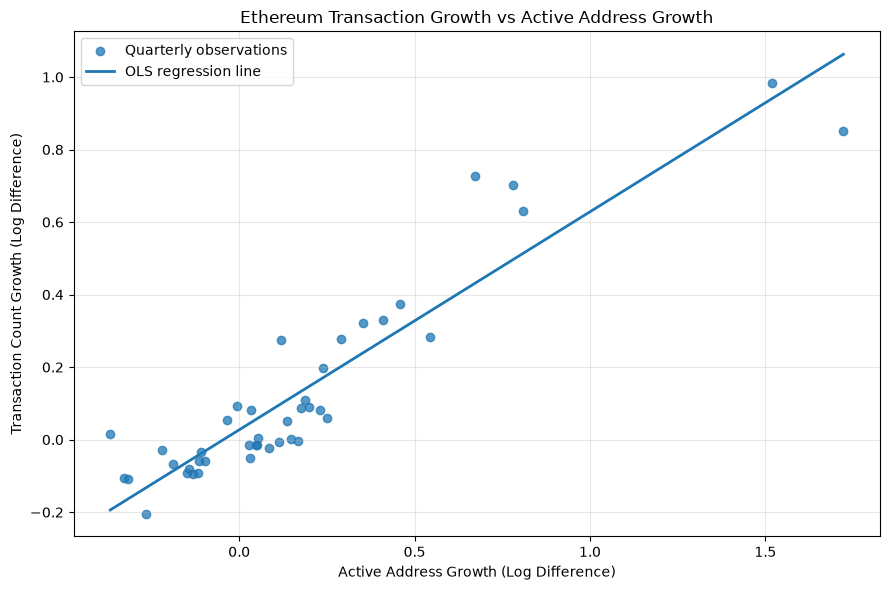

Chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\18_transaction_vs_active_address_growth.png


In [65]:
# visualize the relationship
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Correct project-level folder
project_dir = Path.cwd().parent
visualization_dir = project_dir / "visualizations"
visualization_dir.mkdir(parents=True, exist_ok=True)

x = growth_df["active_addresses"]
y = growth_df["quarter_tx_count"]

# Regression line
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
y_line = intercept + slope * x_line

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(x, y, alpha=0.75, label="Quarterly observations")
ax.plot(x_line, y_line, linewidth=2, label="OLS regression line")

ax.set_title("Ethereum Transaction Growth vs Active Address Growth")
ax.set_xlabel("Active Address Growth (Log Difference)")
ax.set_ylabel("Transaction Count Growth (Log Difference)")
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

# Save before displaying
output_file = visualization_dir / "18_transaction_vs_active_address_growth.png"
fig.savefig(output_file, dpi=300, bbox_inches="tight")

plt.show()
plt.close(fig)

print(f"Chart saved: {output_file}")